# **Exploración de datos**

___

# El Dataset

Este conjunto de datos contiene estudios de resonancia magnética (RM) de rodilla anotados con doce hallazgos comunes: lesiones de ligamentos y meniscos, osteoartritis en tres compartimentos, derrame articular, sinovitis, quiste de Baker, contusión ósea y fractura. Cada estudio comprende una colección de secuencias de RM individuales de una sola sesión de exploración, formateadas como series DICOM.

Los estudios provienen de una variada mezcla internacional de centros de diagnóstico por imágenes y abarcan una amplia gama de escáneres, protocolos y poblaciones. Solo un pequeño subconjunto de estudios de entrenamiento cuenta con etiquetas por afección. También se proporciona el texto original del informe radiológico.

## Estructura del directorio

    data 
    ├── sample_submission.csv 
    ├── test.csv 
    ├── test_series 
    │ㅤㅤ└── <StudyInstanceUID> 
    │ㅤㅤㅤㅤㅤ└── <SeriesInstanceUID> 
    │ㅤㅤㅤㅤㅤㅤㅤㅤ└── <SOPInstanceUID>.dcm
    ├── test_series.csv 
    ├── train.csv 
    ├── train_series 
    │ㅤㅤ└── <StudyInstanceUID> 
    │ㅤㅤㅤㅤㅤ└── <SeriesInstanceUID> 
    │ㅤㅤㅤㅤㅤㅤㅤㅤ└── <SOPInstanceUID>.dcm 
    └── train_series.csv 

## Especificación de archivos

##### **data**
Carpeta principal que contiene los archivos.


##### **sample_submission.csv**
Es un archivo csv como ejemplo de cómo deben ser las predicciones. Son 13 columnas, primero es el ID de una instancia en específico, seguido son 12 columnas donde cada una contiene la probabilidad (0.0 - 1.0) de pertenecer a cada una de las clases. En este caso para ejemplicifación todas fueron establecidas en 0.5 de probabilidad.


##### **test.csv**
Contiene 3 IDs de estudio del set de datos de testeo público. Durante la evaluación este set de datos es reemplazado con los datos de testing reales, los cuales conforman 1300 estudios.


##### **test_series/** 
Archivos DICOM organizados de la siguiente forma: 

        test_series 
    ㅤㅤㅤ└── <StudyInstanceUID> 
    ㅤㅤㅤㅤㅤㅤ└── <SeriesInstanceUID> 
    ㅤㅤㅤㅤㅤㅤㅤㅤ└── <SOPInstanceUID>.dcm


##### **test_series.csv**
Este csv contiene 5 columnas distribuídas de la siguiente forma:
1. StudyInstanceUID. Es el estudio al que pertenecen las series.
2. SeriesInstanceUID. Es el ID de una serie que coincide con la carpeta train_series/\<StudyInstanceUID>.
3. Fluid_Sensitive. Indica "1" si la secuencia se enfoca en señales de líquido (T2, PD, STIR y similares); indica "0" en caso contrario.
4. Fat_Suppression. Indica "1" si la secuencia aplica supresión de grasa; indica "0" en caso contrario.
5. Anatomical_Plane. Indica el plano de la imagen, estos pueden ser "Sagittal", "Coronal" o "Axial".

##### **train.csv**
Cada fila es un estudio para entrenamiento y se divide en las siguientes 14 columnas:
1. StudyInstanceUID. El ID de los estudios.
2. Report. Es el reporte de la radiología, es un reporte por estudio, no uno por serie. Varía el lenguaje en el que está escrito el reporte.
3. ACL. lesión del ligamento cruzado anterior (0/1).
4. MCL. lesión del ligamento colateral medial (0/1).
5. Median Meniscus. rotura del menisco medial (0/1).
6. Lateral Meniscus. rotura del menisco lateral (0/1).
7. Medial OA. osteoartritis del compartimento tibiofemoral medial (0/1).
8. Lateral OA. osteoartritis del compartimento tibiofemoral lateral (0/1).
9. PF OA. osteoartritis patelofemoral (0/1).
10. Effusion: derrame articular / exceso de líquido (0/1).
11. Synovitis: inflamación de la membrana sinovial (0/1).
12. Baker's. quiste de Baker (0/1).
13. Contusion. contusión ósea / hematoma óseo (0/1).
14. Fracture. fractura (0/1).

##### **train_series/**
Igual a la estructura de [test_series](#test_series)

##### **train_series.csv**
Igual a la estructura de [test_series.csv](#test_seriescsv)

## Los archivos DICOM

#### ¿Qué es un archivo DICOM?
DICOM (Digital Imaging and Communications in Medicine) es el formato estándar para guardar y transmitir imágenes médicas. Lo usan los resonadores, tomógrafos y equipos de rayos X de casi cualquier hospital. Cada archivo .dcm tiene dos partes:

1. La imagen: una matriz de píxeles, casi siempre en escala de grises y con más profundidad que una foto normal (12 o 16 bits en lugar de 8).
2. Los metadatos (el header): cientos de campos con información del estudio, por ejemplo:
identificadores (StudyInstanceUID, SeriesInstanceUID, SOPInstanceUID), que son los mismos números largos de tus CSV y nombres de carpetas;
geometría: tamaño del píxel en mm (PixelSpacing), grosor del corte (SliceThickness), posición y orientación del corte en el espacio (ImagePositionPatient, ImageOrientationPatient);
parámetros de adquisición: tiempos de la secuencia de resonancia (RepetitionTime, EchoTime), el fabricante del equipo, la descripción de la secuencia;
el orden del corte (InstanceNumber).

#### Estructura de nuestros archivos DICOM
**\<StudyInstanceUID>/** \
Identifica el estudio, una visita del paciente al resonador para revisar una rodilla. Es la unidad de predicción: cada renglón de train.csv y de submission.csv es un estudio con sus 12 etiquetas.

**\<SeriesInstanceUID>/** \
Identifica una serie dentro del estudio, es decir, una secuencia adquirida con un plano y un contraste determinados (por ejemplo, sagital con supresión de grasa).

**\<SOPInstanceUID>.dcm** \
Identifica una instancia, una sola rebanada (slice) dentro de la serie. Cada archivo .dcm lleva este identificador como nombre. SOP viene de Service-Object Pair, un término del estándar que aquí basta con leer como "imagen individual".

**En resumen** \
Cada carpeta **\<StudyInstanceUID>/** contiene un estudio, o sea, una visita de un paciente. Cabe aclarar que un paciente puede tener más de un estudio (no se especifica en Kaggle si esto pasa). \
Cada carpeta **\<SeriesInstanceUID>/** es una serie que contiene múltiples archivos *.dcm* que pertenecen a una sola secuencia y cada secuencia puede ser sagital, coronal o axial, con y sin supresión de grasa, sensible o no a fluídos. \
Cada **\<SOPInstanceUID>.dcm** es una rebanada 2D de una serie.

___

___

___

# Preprocesamiento para el EDA - Consiguiendo la metadata

Viendo la información que podíamos conseguir de los archivos DICOM nos dimos cuenta de la gran cantidad de metadata con la que cuentan estos, así que para facilitar la exploración de los datos decidimos crear un archivo .csv que tenga toda la información de los archivos, esto nos ayudará a tener un solo dataframe con el que podamos realizar la exploración de distribuciones, histogramas, etiquetas, dimensiones, etc. \
No solo centralizamos la información, hacemos una exploración de una forma mas eficiente.

In [1]:
from pathlib import Path
from rsna_knee.metadatos import extraer_metadatos

RAW = Path("../data/raw")
PROCESSED = Path("../data/processed")

meta_train = extraer_metadatos(RAW / "train_series")
meta_train.to_csv(PROCESSED / "metadatos_train.csv", index=False)
meta_train.shape

100%|██████████| 24371/24371 [00:07<00:00, 3272.11it/s]


(24371, 36)

### Cargamos nuestros datos

In [2]:
import pandas as pd
import matplotlib.pyplot as plt
from catppuccin import PALETTE
plt.style.use("catppuccin.mocha")

train = pd.read_csv(RAW / "train.csv")
train_series = pd.read_csv(RAW / "train_series.csv")
meta = pd.read_csv(PROCESSED / "metadatos_train.csv", low_memory=False)

___

___

___

# EDA

Nuestro EDA se enfocará principalmente en dos partes: las resonancias magnéticas (MRI) y los reportes de cada serie

No se tiene la intención de hacer un EDA demasiado profundo, nuestra intención es la de hacer un EDA que reponda a las necesidades del modelo que queremos construir, así que nos vamos a centrar **únicamente en los datos que vemos relevantes**.

___

## 1. Resonancias

### 1.1. Estudios

#### 1.1.1. Cantidad de estudios

In [3]:
print("Estudios en train.csv:", train["StudyInstanceUID"].nunique())
print("Estudios con imágenes:", meta["StudyInstanceUID"].nunique())
print("Coinciden:", set(train["StudyInstanceUID"]) == set(meta["StudyInstanceUID"]))

Estudios en train.csv: 4407
Estudios con imágenes: 4407
Coinciden: True


Cómo se menciona en la página de la competencia, la cantidad de estudios en nuestro dataset coincide con la información que otorga Kaggle.

#### 1.1.2. Distribución de series por estudio

In [4]:
series_por_estudio = meta.groupby("StudyInstanceUID").size()
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4), dpi=320)

conteo = series_por_estudio.value_counts().sort_index()
print(series_por_estudio.describe())
ax1.bar(conteo.index, conteo.values)
ax1.set_xlabel("Series por estudio")
ax1.set_ylabel("Número de estudios")
ax1.set_title("Distribución")

ax2.boxplot(series_por_estudio, vert=False)
ax2.set_xlabel("Series por estudio")
ax2.set_yticks([])
ax2.set_title("Boxplot")

plt.tight_layout()
plt.show()

# Cuántos marca como outliers la regla 1.5×IQR
q1, q3 = series_por_estudio.quantile([0.25, 0.75])
iqr = q3 - q1
outliers = series_por_estudio[(series_por_estudio < q1 - 1.5*iqr) | (series_por_estudio > q3 + 1.5*iqr)]
print(f"Outliers: {len(outliers)} estudios ({len(outliers)/len(series_por_estudio):.1%})")

count    4407.000000
mean        5.530066
std         1.393826
min         3.000000
25%         5.000000
50%         5.000000
75%         6.000000
max        14.000000
dtype: float64


<Figure size 3840x1280 with 2 Axes>

Outliers: 425 estudios (9.6%)


**Hallazgos relevantes**
- Existe un estudio que tiene 3 series, siendo este el único que cuenta con esta cantidad.
- Hay 2299 estudios que cuentan con 5 series, por lo que 5 representa la media de series.
- 29 estudios cuentan con más de 11 series
- El mínimo de series es 3 y el máximo 14

### 1.2. Series

#### 1.2.1. Cantidad de series

In [5]:
print("Series en metadatos:", meta["SeriesInstanceUID"].nunique())
print("Series en train_series.csv:", train_series["SeriesInstanceUID"].nunique())
print("Coinciden:", set(meta["SeriesInstanceUID"]) == set(train_series["SeriesInstanceUID"]))

Series en metadatos: 24371
Series en train_series.csv: 24371
Coinciden: True


#### 1.2.2. Distribución de archivos .dcm de las series

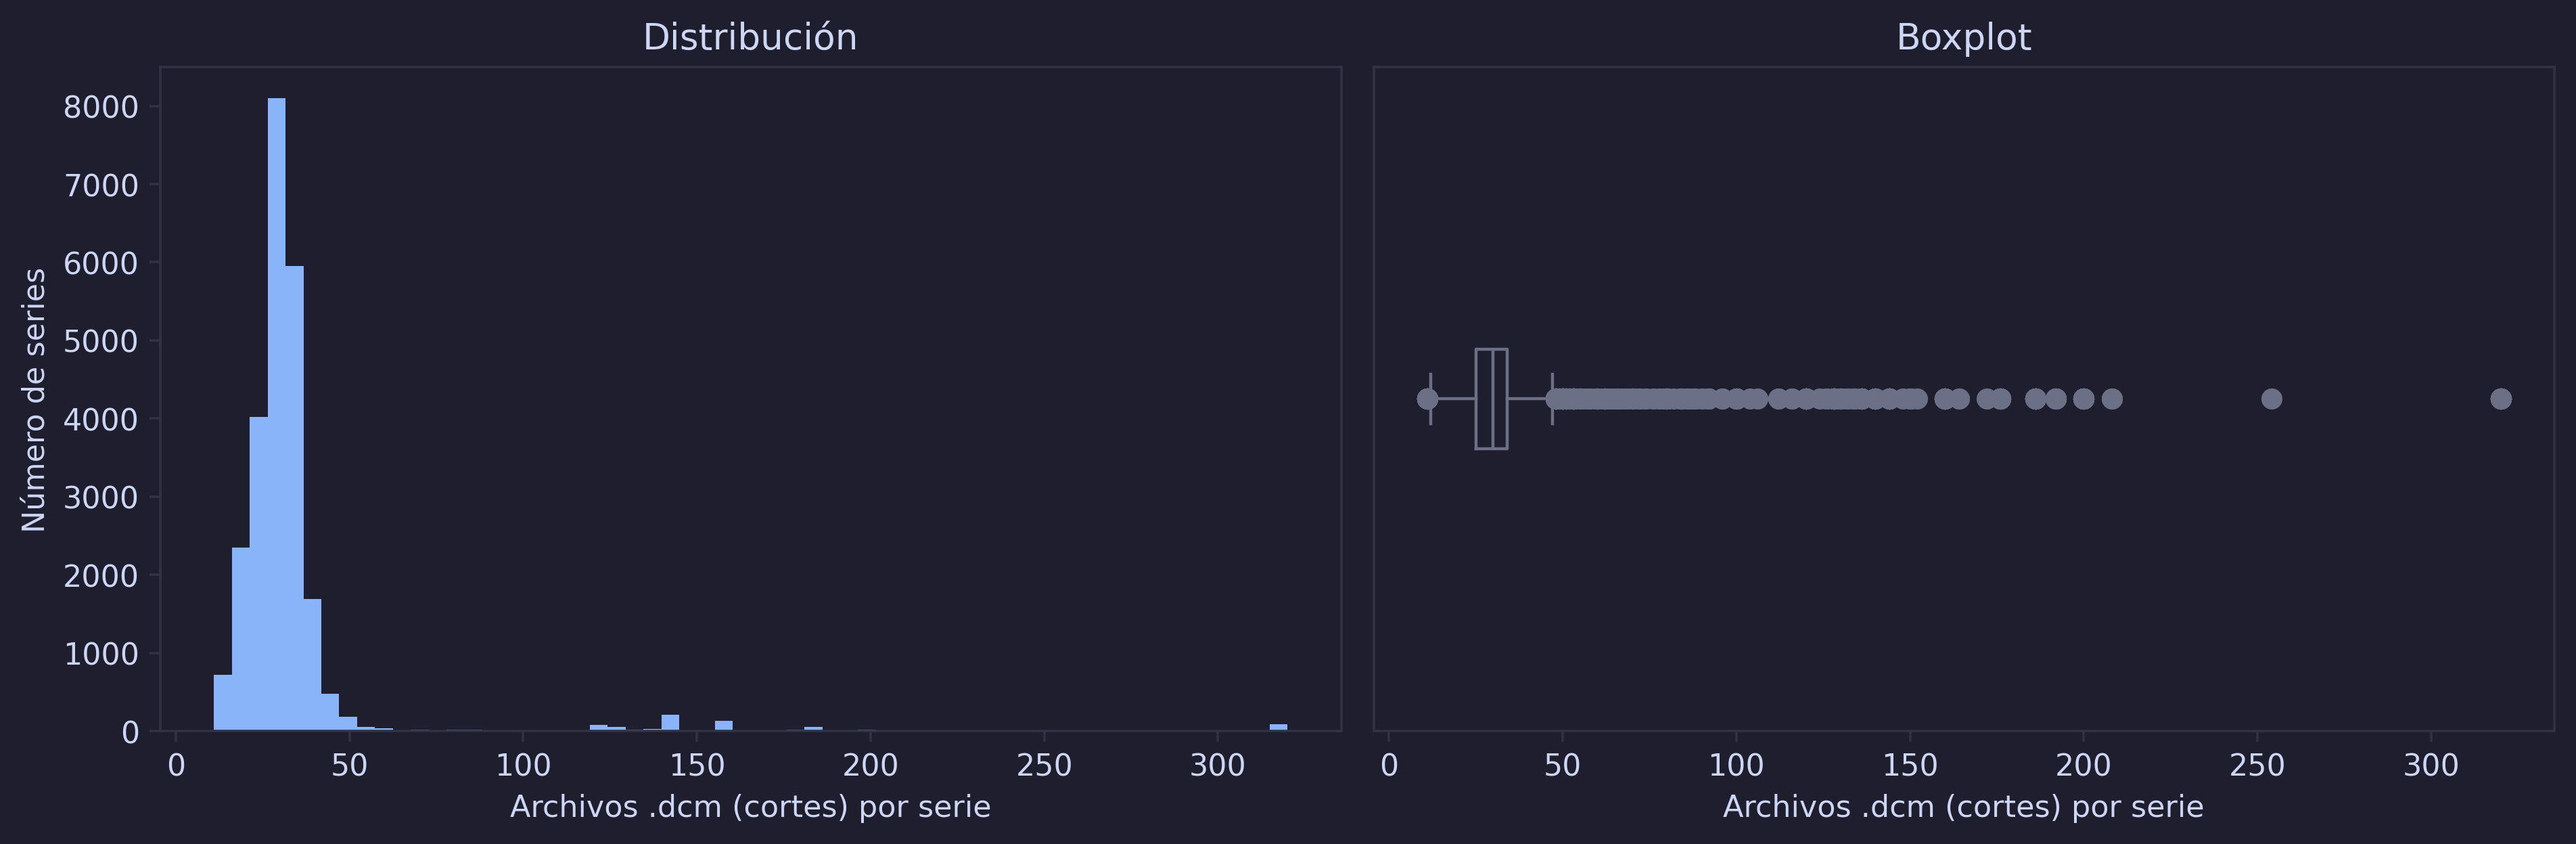

count    24371.000000
mean        33.608715
std         26.575246
min         11.000000
25%         25.000000
50%         30.000000
75%         34.000000
max        320.000000
Name: n_dcm, dtype: float64
Total de archivos .dcm: 819078


In [6]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4), dpi=320)

ax1.hist(meta["n_dcm"], bins=60)
ax1.set_xlabel("Archivos .dcm (cortes) por serie")
ax1.set_ylabel("Número de series")
ax1.set_title("Distribución")

ax2.boxplot(meta["n_dcm"], vert=False)
ax2.set_xlabel("Archivos .dcm (cortes) por serie")
ax2.set_yticks([])
ax2.set_title("Boxplot")

plt.tight_layout()
plt.show()

print(meta["n_dcm"].describe())
print("Total de archivos .dcm:", meta["n_dcm"].sum())

In [7]:
meta.groupby("MRAcquisitionType")["n_dcm"].describe()

,count,mean,std,min,25%,50%,75%,max
MRAcquisitionType,,,,,,,,
2D,22329.0,29.632765,6.463298,11.0,26.0,30.0,33.0,60.0
3D,836.0,154.746411,64.786820,50.0,120.0,144.0,160.0,320.0


#### 1.2.3. Distribución de secuencias (anatomical plane)

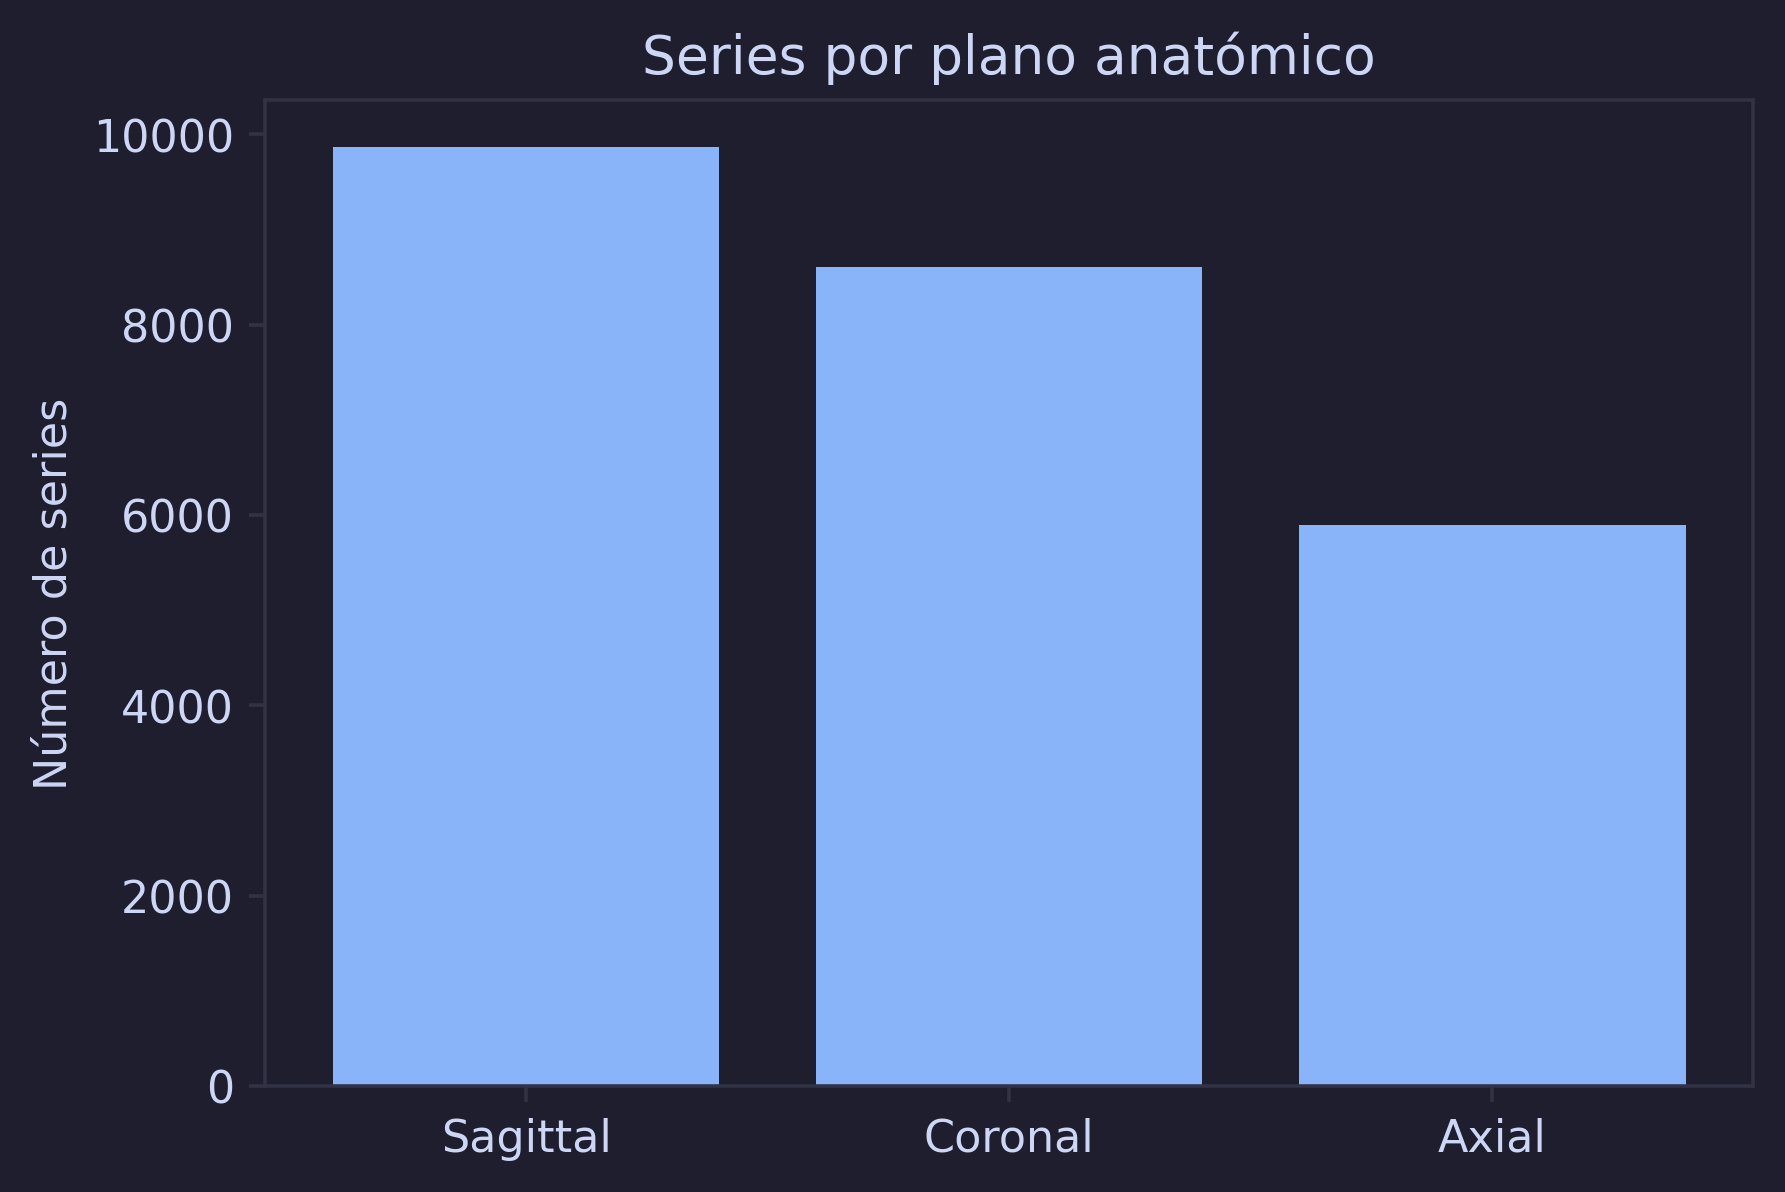

Anatomical_Plane
3    4407
Name: count, dtype: int64


In [8]:
series = meta.merge(train_series, on=["StudyInstanceUID", "SeriesInstanceUID"])

conteo_planos = series["Anatomical_Plane"].value_counts()
plt.figure(figsize=(6, 4), dpi=320)
plt.bar(conteo_planos.index, conteo_planos.values)
plt.ylabel("Número de series")
plt.title("Series por plano anatómico")
plt.show()

# ¿Cuántos estudios tienen los 3 planos?
planos_por_estudio = series.groupby("StudyInstanceUID")["Anatomical_Plane"].nunique()
print(planos_por_estudio.value_counts())

### 1.3. Archivos .dcm

#### 1.3.1. Cantidad de arcivos .dcm

In [9]:
print("Total de archivos .dcm:", meta["n_dcm"].sum())

Total de archivos .dcm: 819078


##### 1.3.1.1. Primer vistazo

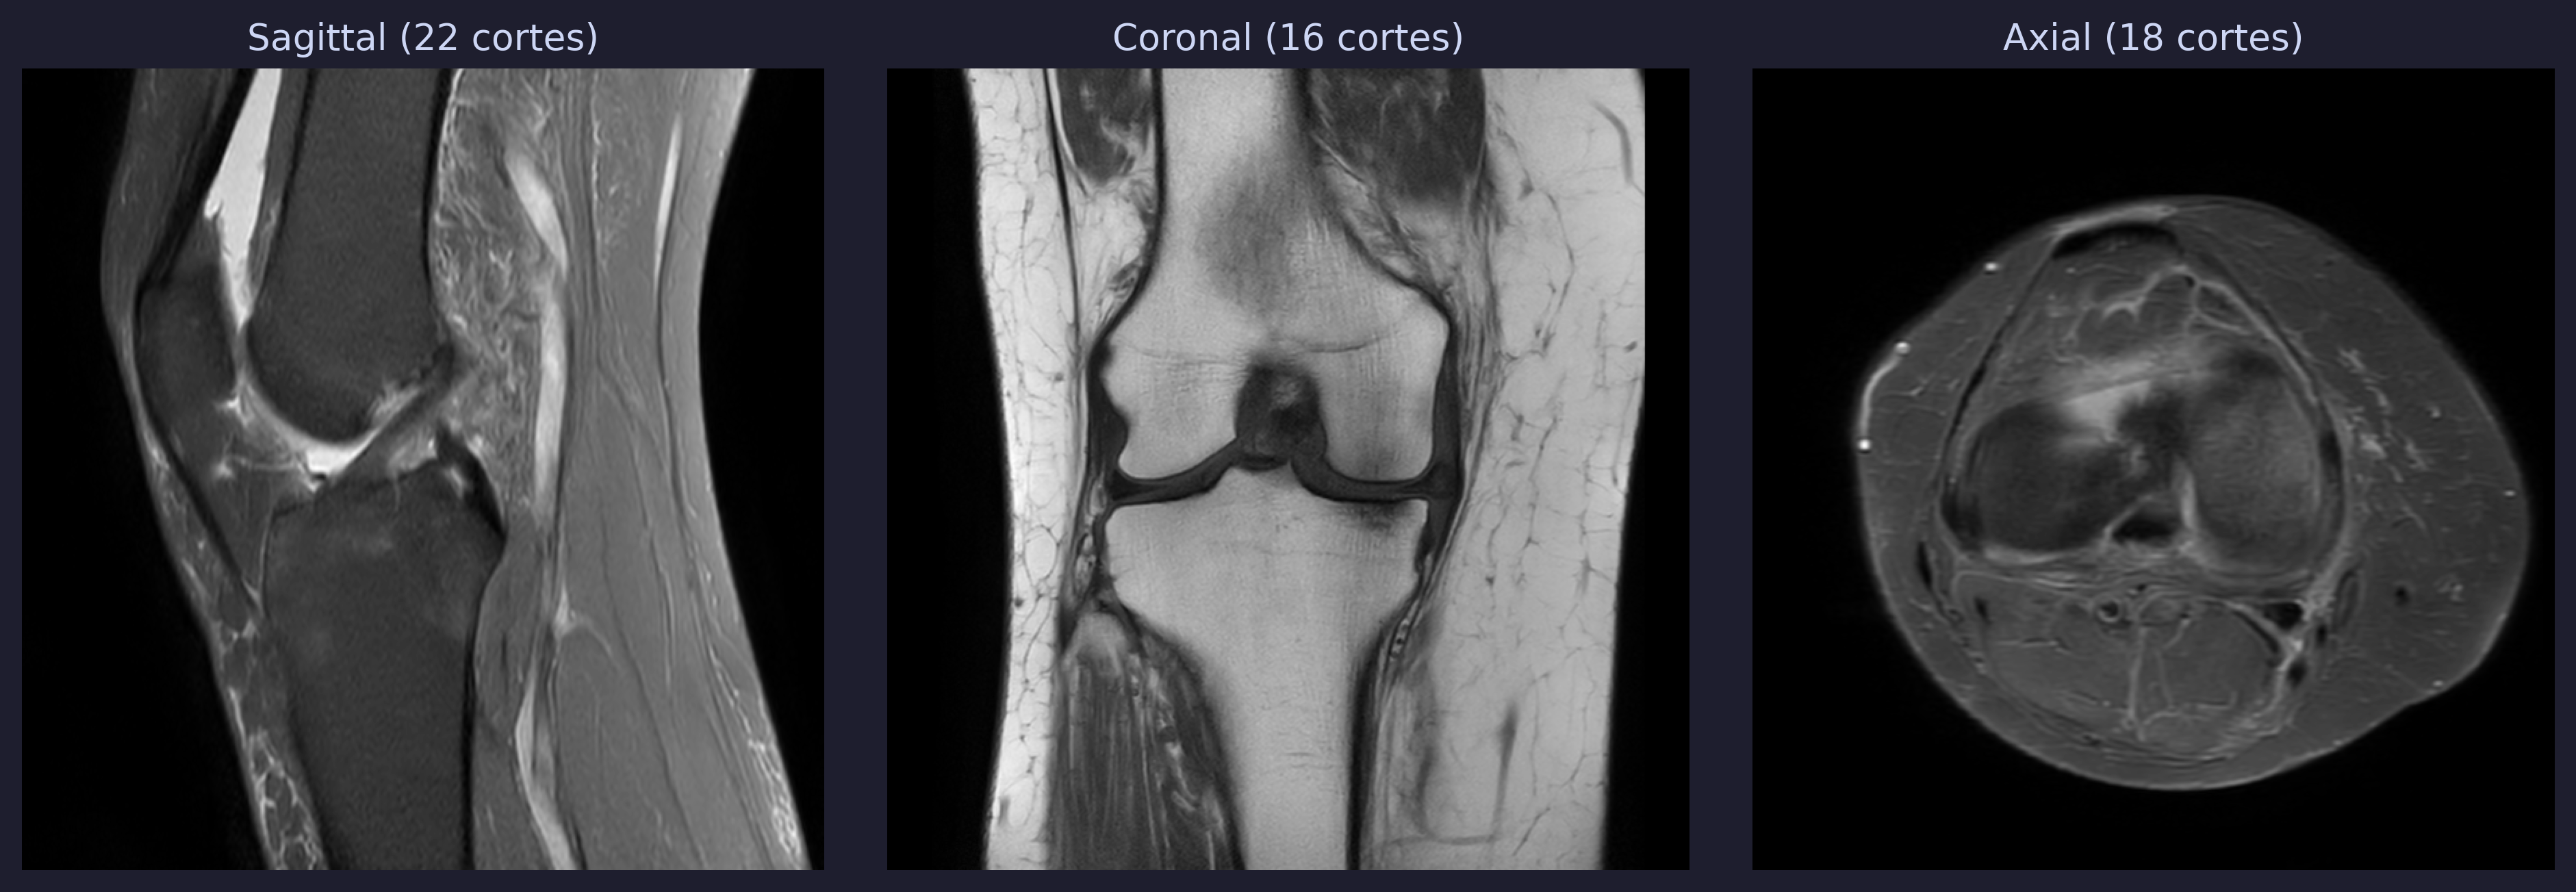

In [10]:
import pydicom

estudio = train_series["StudyInstanceUID"].iloc[0]

def leer_cortes(estudio, serie):
    """Lee todos los cortes de una serie, ordenados por InstanceNumber."""
    archivos = (RAW / "train_series" / estudio / serie).glob("*.dcm")
    cortes = [pydicom.dcmread(f) for f in archivos]
    return sorted(cortes, key=lambda d: int(d.InstanceNumber))

fig, axs = plt.subplots(1, 3, figsize=(12, 4), dpi=320)
for ax, plano in zip(axs, ["Sagittal", "Coronal", "Axial"]):
    fila = train_series[(train_series["StudyInstanceUID"] == estudio) &
                        (train_series["Anatomical_Plane"] == plano)].iloc[0]
    cortes = leer_cortes(estudio, fila["SeriesInstanceUID"])
    medio = cortes[len(cortes) // 2]
    ax.imshow(medio.pixel_array, cmap="gray")
    ax.set_title(f"{plano} ({len(cortes)} cortes)")
    ax.axis("off")
plt.tight_layout()
plt.show()

#### 1.3.2. Pacientes

##### 1.3.2.1. Pacientes únicos

In [11]:
print("Pacientes únicos:", meta["PatientID"].nunique())
print(meta.groupby("PatientID")["StudyInstanceUID"].nunique().value_counts())

Pacientes únicos: 4407
StudyInstanceUID
1    4407
Name: count, dtype: int64


##### 1.3.2.2 Sexo y 1.3.2.3 Lateralidad

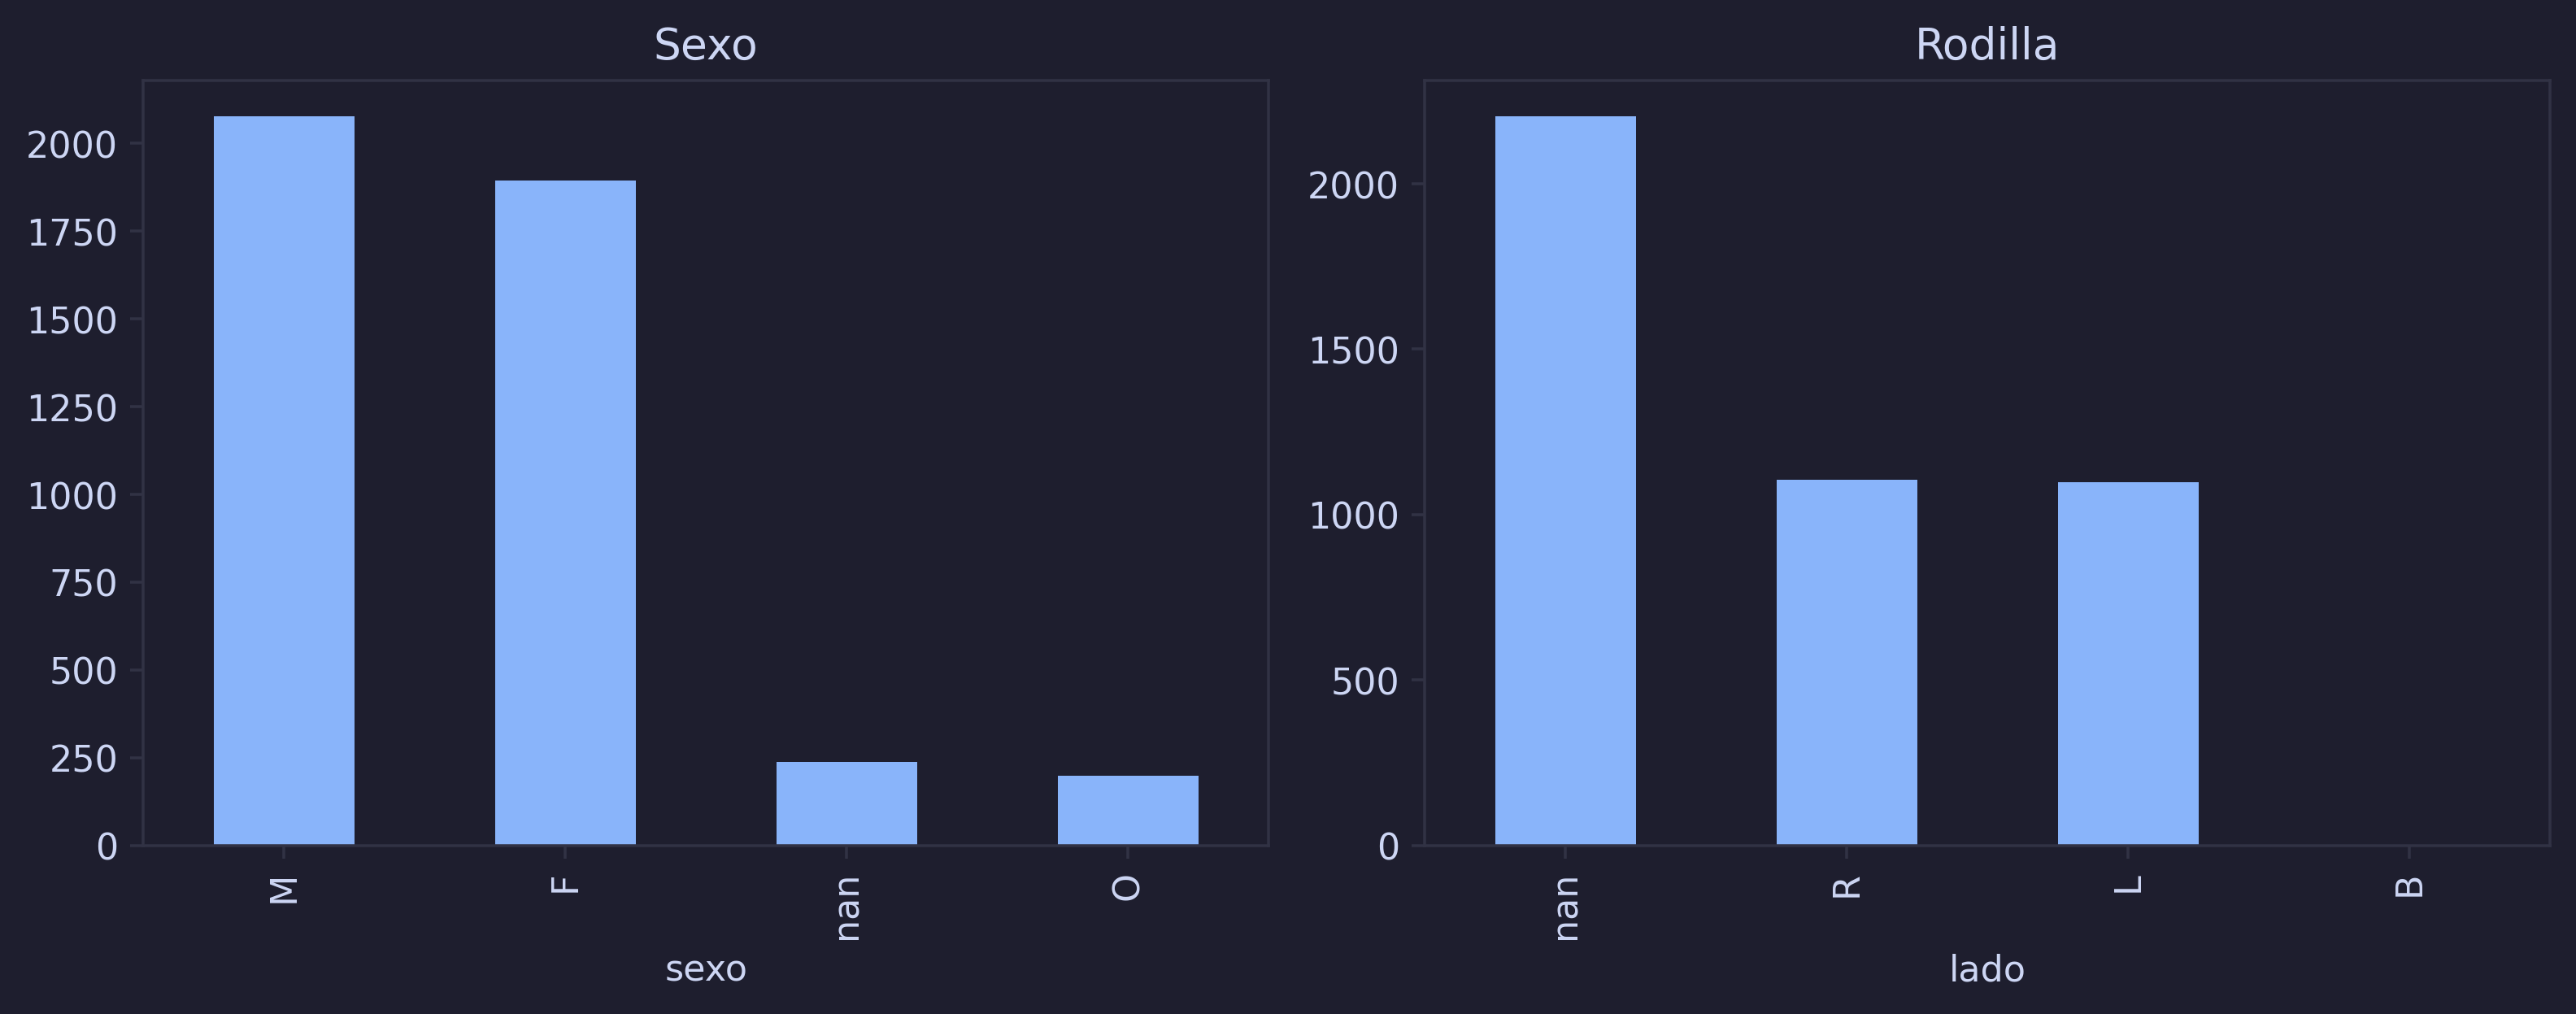

In [12]:
por_estudio = meta.groupby("StudyInstanceUID").agg(
    sexo=("PatientSex", "first"),          # first ignora los NaN
    lado=("Laterality", "first"),
)
por_estudio["lado"] = por_estudio["lado"].replace({"LEFT": "L", "RIGHT": "R"})

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 4), dpi=320)
por_estudio["sexo"].value_counts(dropna=False).plot.bar(ax=ax1, title="Sexo")
por_estudio["lado"].value_counts(dropna=False).plot.bar(ax=ax2, title="Rodilla")
plt.tight_layout()
plt.show()

#### 1.3.3. Geometría y resolución

Esta sección será primordial para la estandarización de los datos y lo que realmente nos dará a conocer cómo se componen las resonancias.

##### 1.3.3.1. Rows y Columns

Dicho en otras palabras esta parte se refiere a la resoluión de las imágenes.

Resoluciones distintas: 221
Series no cuadradas: 1769


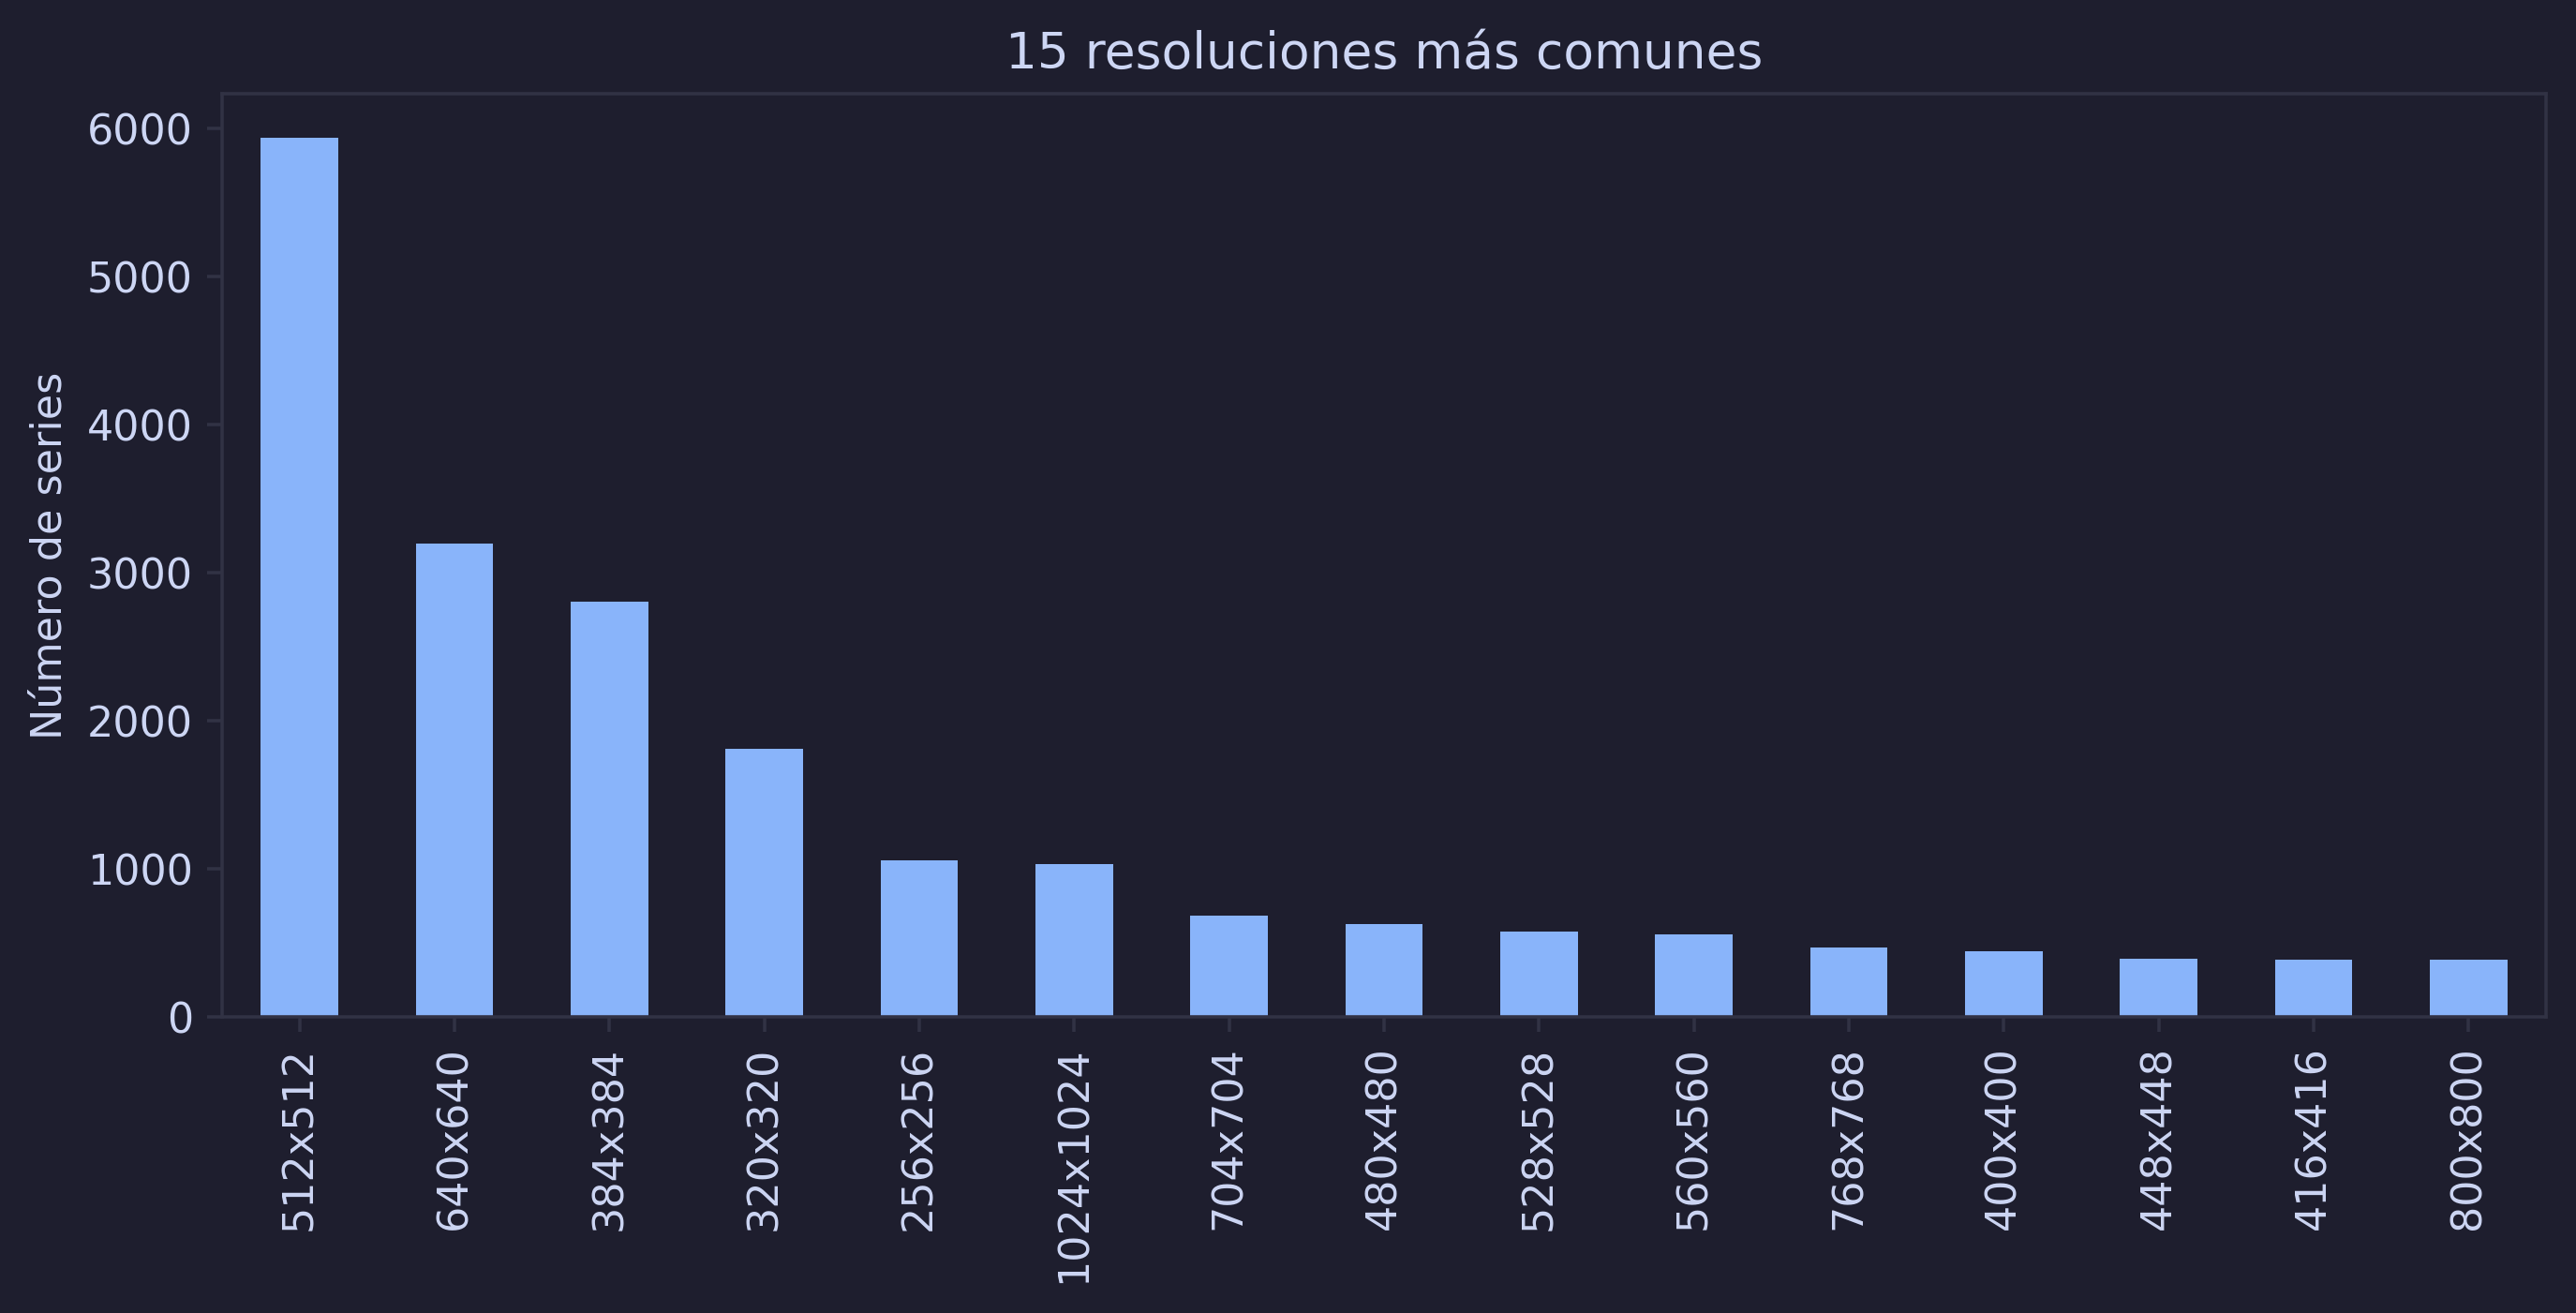

In [13]:
resol = meta["Rows"].astype(str) + "x" + meta["Columns"].astype(str)
print("Resoluciones distintas:", resol.nunique())
print("Series no cuadradas:", (meta["Rows"] != meta["Columns"]).sum())

plt.figure(figsize=(10, 4), dpi=320)
resol.value_counts().head(15).plot.bar()
plt.ylabel("Número de series")
plt.title("15 resoluciones más comunes")
plt.show()

##### 1.3.3.2. Pixel Spacing

El Pixel Spacing se refiere al tamaño físico de cada píxel en milímetros. Este trae dos valores: La distancia entre filas y columnas. \
Es decir, el alto y ancho de cada píxel. Por ejemplo 0.1562/0.1562 significa que cada píxel representa un cuadro de 0.156 x 0.156 mm del cuerpo del paciente.

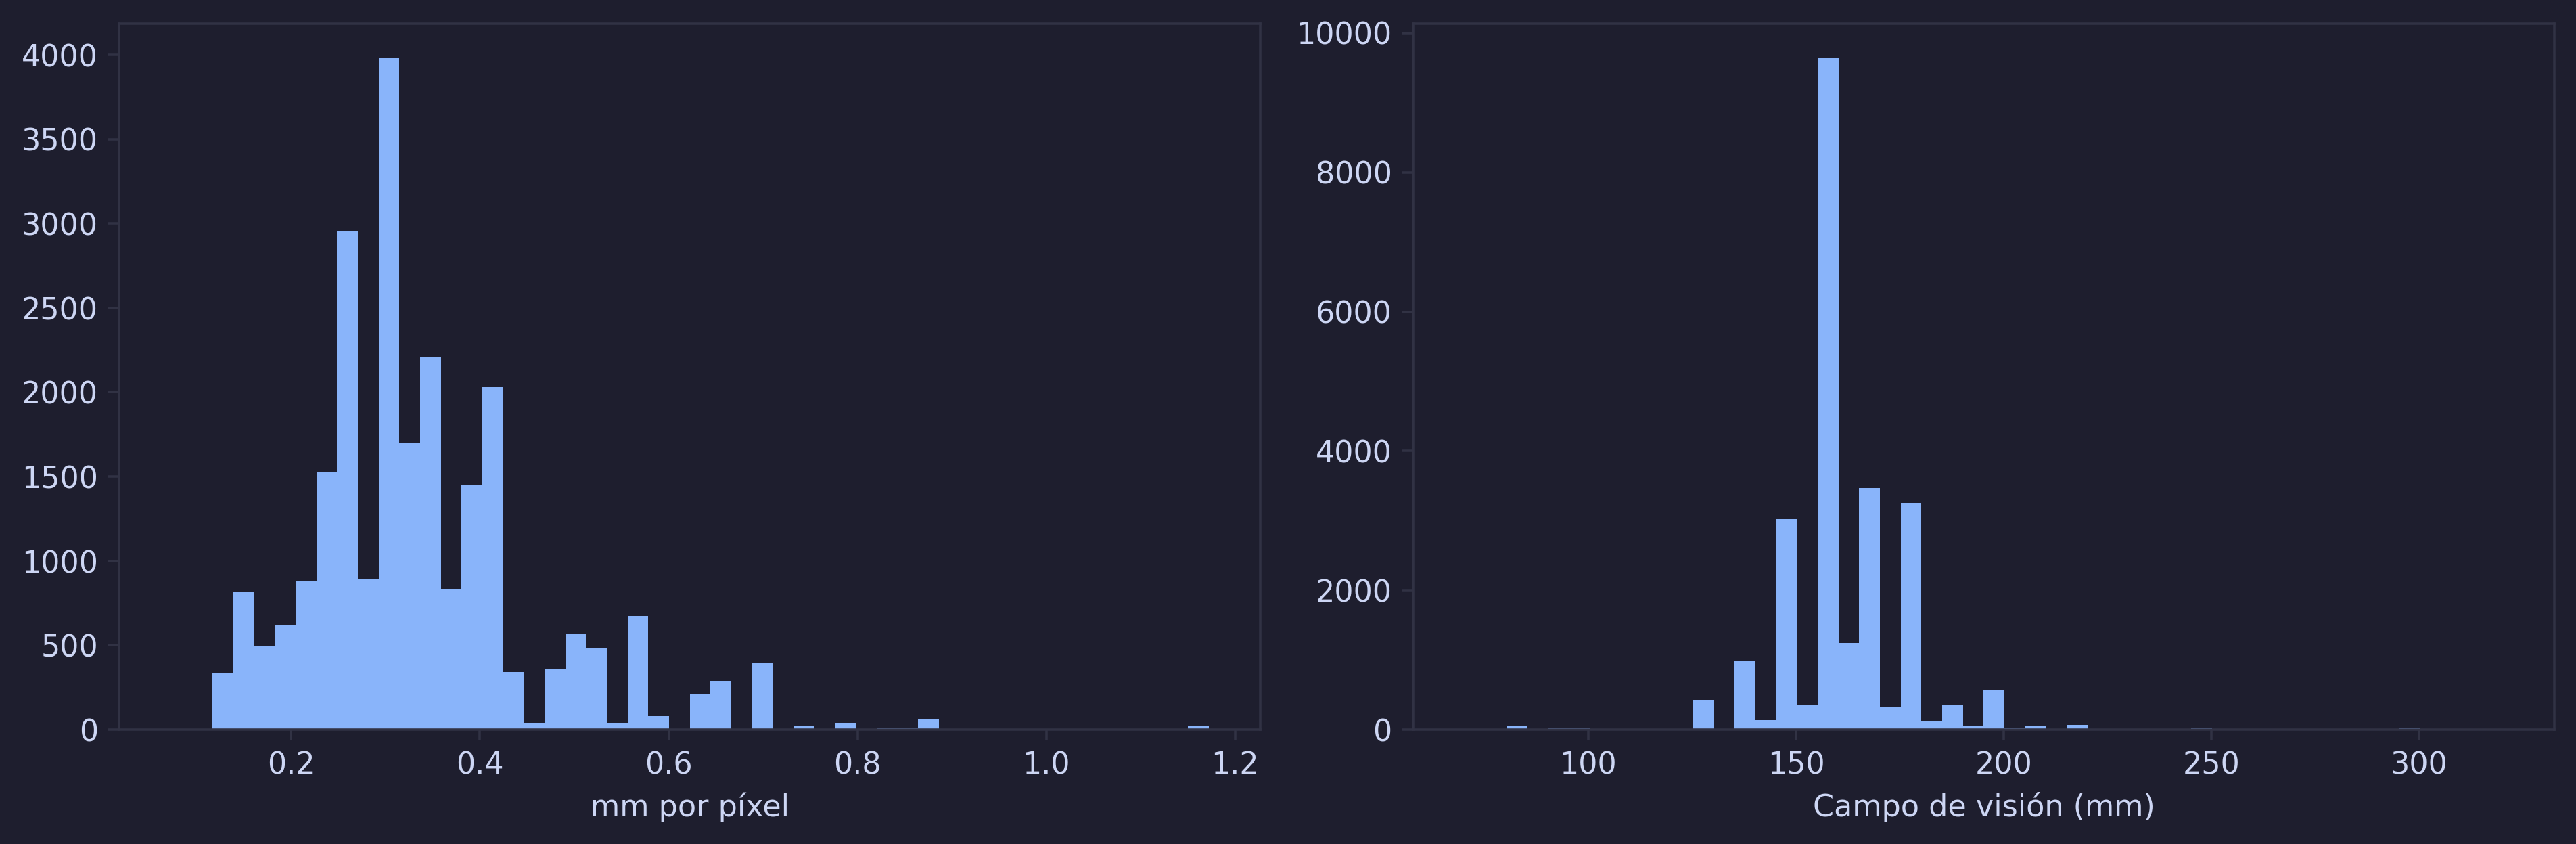

In [14]:
spacing = meta["PixelSpacing"].str.split("\\", expand=True).astype(float)
meta["spacing_mm"] = spacing[0]
meta["fov_mm"] = meta["Rows"] * meta["spacing_mm"]   # tamaño real de la imagen

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4), dpi=320)
ax1.hist(meta["spacing_mm"], bins=50); ax1.set_xlabel("mm por píxel")
ax2.hist(meta["fov_mm"], bins=50);     ax2.set_xlabel("Campo de visión (mm)")
plt.tight_layout()
plt.show()

En el "campo de visión" nos referimos al tamaño real, en milímetros, de la región del cuerpo que aparece en la image. Se calcula multiplicando el número de píxeles por el tamaño de cada píxel.

Este es un apartado en el que tendremos que redimensionar las imágenes para que todas tengan la misma dimensión. Específicamente a 160x160.

##### 1.3.3.3. Slice Thinckness y Spacing Between Slices

**Slice Thickness** \
Es el grosor del corte en milímetros: cuánto tejido "abarca" cada imagen en la dirección perpendicular a ella. Una resonancia no toma una foto plana, sino que cada imagen resume una rebanada con cierto grosor, por ejemplo 3 mm.

**Spacing Between Slices** \
Es la distancia en milímetros entre el centro de un corte y el centro del siguiente. Si es mayor que el grosor, queda un hueco (gap) de tejido que no se captura. Por ejemplo, con 3 mm de grosor y 3.3 mm de espaciado quedan 0.3 mm sin ver entre cada par de cortes. Si es menor, los cortes se solapan.

In [15]:
meta["gap_mm"] = meta["SpacingBetweenSlices"] - meta["SliceThickness"]
print(meta[["SliceThickness", "SpacingBetweenSlices", "gap_mm"]].describe())

       SliceThickness  SpacingBetweenSlices        gap_mm
count    24371.000000          22792.000000  22792.000000
mean         3.156007              3.704485      0.548104
std          0.628555              0.835289      0.471964
min          0.600000              0.400000     -1.600000
25%          3.000000              3.300000      0.300000
50%          3.000000              3.500000      0.500000
75%          3.500000              4.095000      0.600000
max          6.000000              8.328000      5.081000


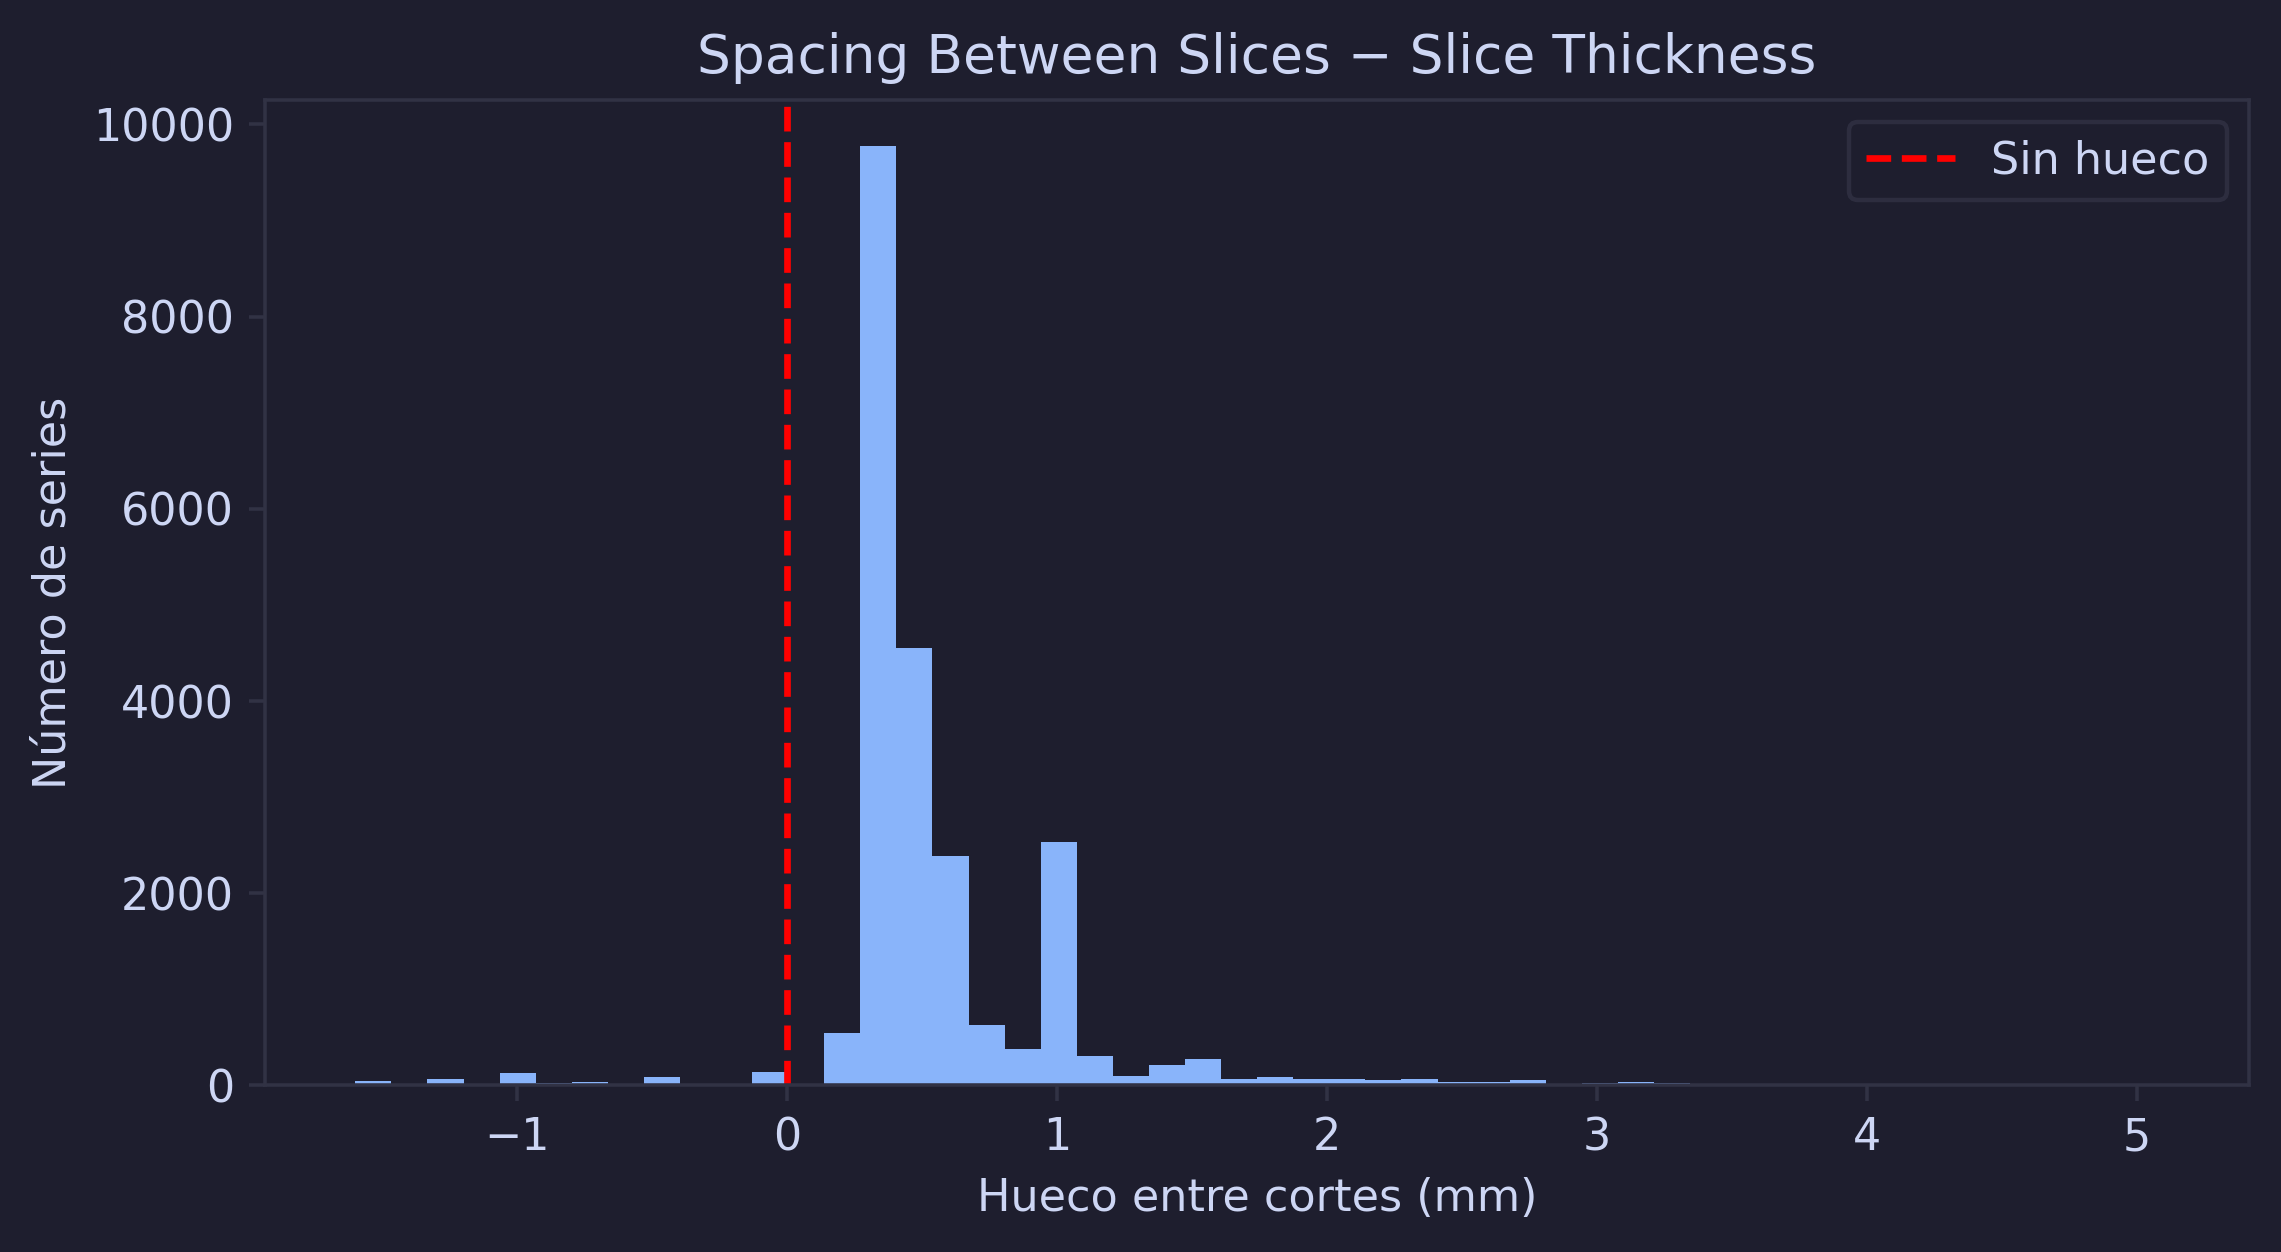

In [16]:
plt.figure(figsize=(8, 4), dpi=320)
plt.hist(meta["gap_mm"].dropna(), bins=50)
plt.axvline(0, color="red", linestyle="--", label="Sin hueco")
plt.xlabel("Hueco entre cortes (mm)")
plt.ylabel("Número de series")
plt.title("Spacing Between Slices − Slice Thickness")
plt.legend()
plt.show()

#### 1.3.4. Intensidad

##### 1.3.4.1. Bits Stores y Pixel Representation

**Bits Stored** \
Es la cantidad de bits que realmente se usan para guardar el valor de cada píxel, y define el rango de valores posibles. Con 12 bits, un píxel puede valer entre 0 y 4095 (2¹² − 1); con 16 bits, el rango llega hasta 65 535. Aunque cada píxel ocupe 16 bits en el archivo (Bits Allocated), a veces solo se usan 12.

**Pixel Representation** \
Indica si los valores tienen signo. Con 0 son sin signo, así que nunca son negativos. Con 1 son con signo, así que pueden ser negativos: con 16 bits, el rango va de −32 768 a 32 767.

In [17]:
print(pd.crosstab(meta["BitsStored"], meta["PixelRepresentation"]))
print(pd.crosstab(meta["Manufacturer"], meta["BitsStored"]))

PixelRepresentation      0     1
BitsStored                      
12                   17927     0
16                     187  6257
BitsStored                         12    16
Manufacturer                               
CANON_MEC                           0   328
FUJIFILM Healthcare Corporation    88     0
GE MEDICAL SYSTEMS                  0  4914
GEHC                                0   187
Hitachi Medical Corporation        42     0
Philips                          3502     0
Philips Healthcare                495     0
Philips Medical Systems          3614     0
SIEMENS                          4460     0
Siemens                           417     0
Siemens Healthineers             5309     0
TOSHIBA                             0  1015


##### 1.3.4.2. Windows Center y Window Width

Una imagen de resonancia tiene miles de valores de intensidad posibles, pero una pantalla solo muestra unos 256 tonos de gris. La ventana indica qué tramo de valores mostrar. Window Center es el valor que se ve como gris medio, y Window Width es el ancho del tramo. Por ejemplo, con centro 1126 y ancho 2282, los valores de 0 a 2267 se reparten en la escala de grises; los menores se ven negros y los mayores blancos. Es la recomendación del equipo o del técnico para que la imagen se vea bien, y no cambia los datos.

En nuestros datos, el centro va de 5 a 64 666 y el ancho de 11 a 112 411. Esa variación enorme confirma que cada equipo usa escalas de intensidad muy distintas.

In [18]:
print(meta[["WindowCenter", "WindowWidth"]].describe())

       WindowCenter    WindowWidth
count  24371.000000   24371.000000
mean    1052.797116    2127.911129
std     1530.494709    3130.710171
min        5.000000      11.000000
25%      319.000000     660.000000
50%      637.000000    1244.000000
75%     1080.000000    1985.500000
max    64666.000000  112411.000000


##### 1.3.4.3. Rescale Slope y Rescale Intercept

Son los coeficientes de una transformación lineal que convierte el valor guardado en el archivo al valor real: valor real = valor guardado × slope + intercept. En tomografía es esencial, porque convierte a unidades Hounsfield. En resonancia casi siempre vale slope = 1 e intercept = 0, es decir, no cambia nada.

En nuestros datos, el intercept siempre es 0 o falta. El slope es 1 o falta, excepto en unas 4200 series de Philips, que tienen valores como 2.23 o 2.70. Como de todos modos normalizaremos cada serie por separado, multiplicar todos sus valores por una constante no cambia el resultado, así que no hace falta aplicar esta transformación.

In [19]:
print(meta["RescaleSlope"].value_counts(dropna=False).head())
print(meta.loc[meta["RescaleSlope"].notna() & (meta["RescaleSlope"] != 1), "Manufacturer"].value_counts())

RescaleSlope
NaN         14464
1.000000     5726
2.234921        3
2.704762        3
2.411966        3
Name: count, dtype: int64
Manufacturer
Philips Medical Systems    2398
Philips                    1294
Philips Healthcare          489
Name: count, dtype: int64


##### 1.3.4.4. Photometric Interpretation

Photometric Interpretation indica cómo interpretar los valores de los píxeles para mostrarlos como imagen. En imágenes en escala de grises hay dos opciones:

MONOCHROME2: el valor más bajo se ve negro y el más alto blanco. Es la convención normal.
MONOCHROME1: al revés, el valor más bajo se ve blanco. Es común en algunas radiografías.

Para nuestro caso todas las resonancias se encuentran en MONOCHROME2

In [20]:
print(meta["PhotometricInterpretation"].value_counts())

PhotometricInterpretation
MONOCHROME2    24371
Name: count, dtype: int64


___

## 2. Reportes

### 2.1. Un vistazo a los reportes

In [21]:
largo = train["Report"].str.split().str.len()
print(largo.describe())
print(train["Report"].str.findall(r"\[[A-Z_ ]+\]").explode().value_counts().head())

count    4407.000000
mean      147.543000
std        95.329697
min         8.000000
25%        74.500000
50%       129.000000
75%       202.000000
max       690.000000
Name: Report, dtype: float64
Report
[DATE]        710
[TIME]        359
[REDACTED]    110
[ID]           94
[NAME]         38
Name: count, dtype: int64


- El número de reportes coincide con el de nuestros estudios.
- No existen reportes vacíos.
- Van desde las 8 hasta las 690 palabras.

### 2.2. Idiomas encontrados

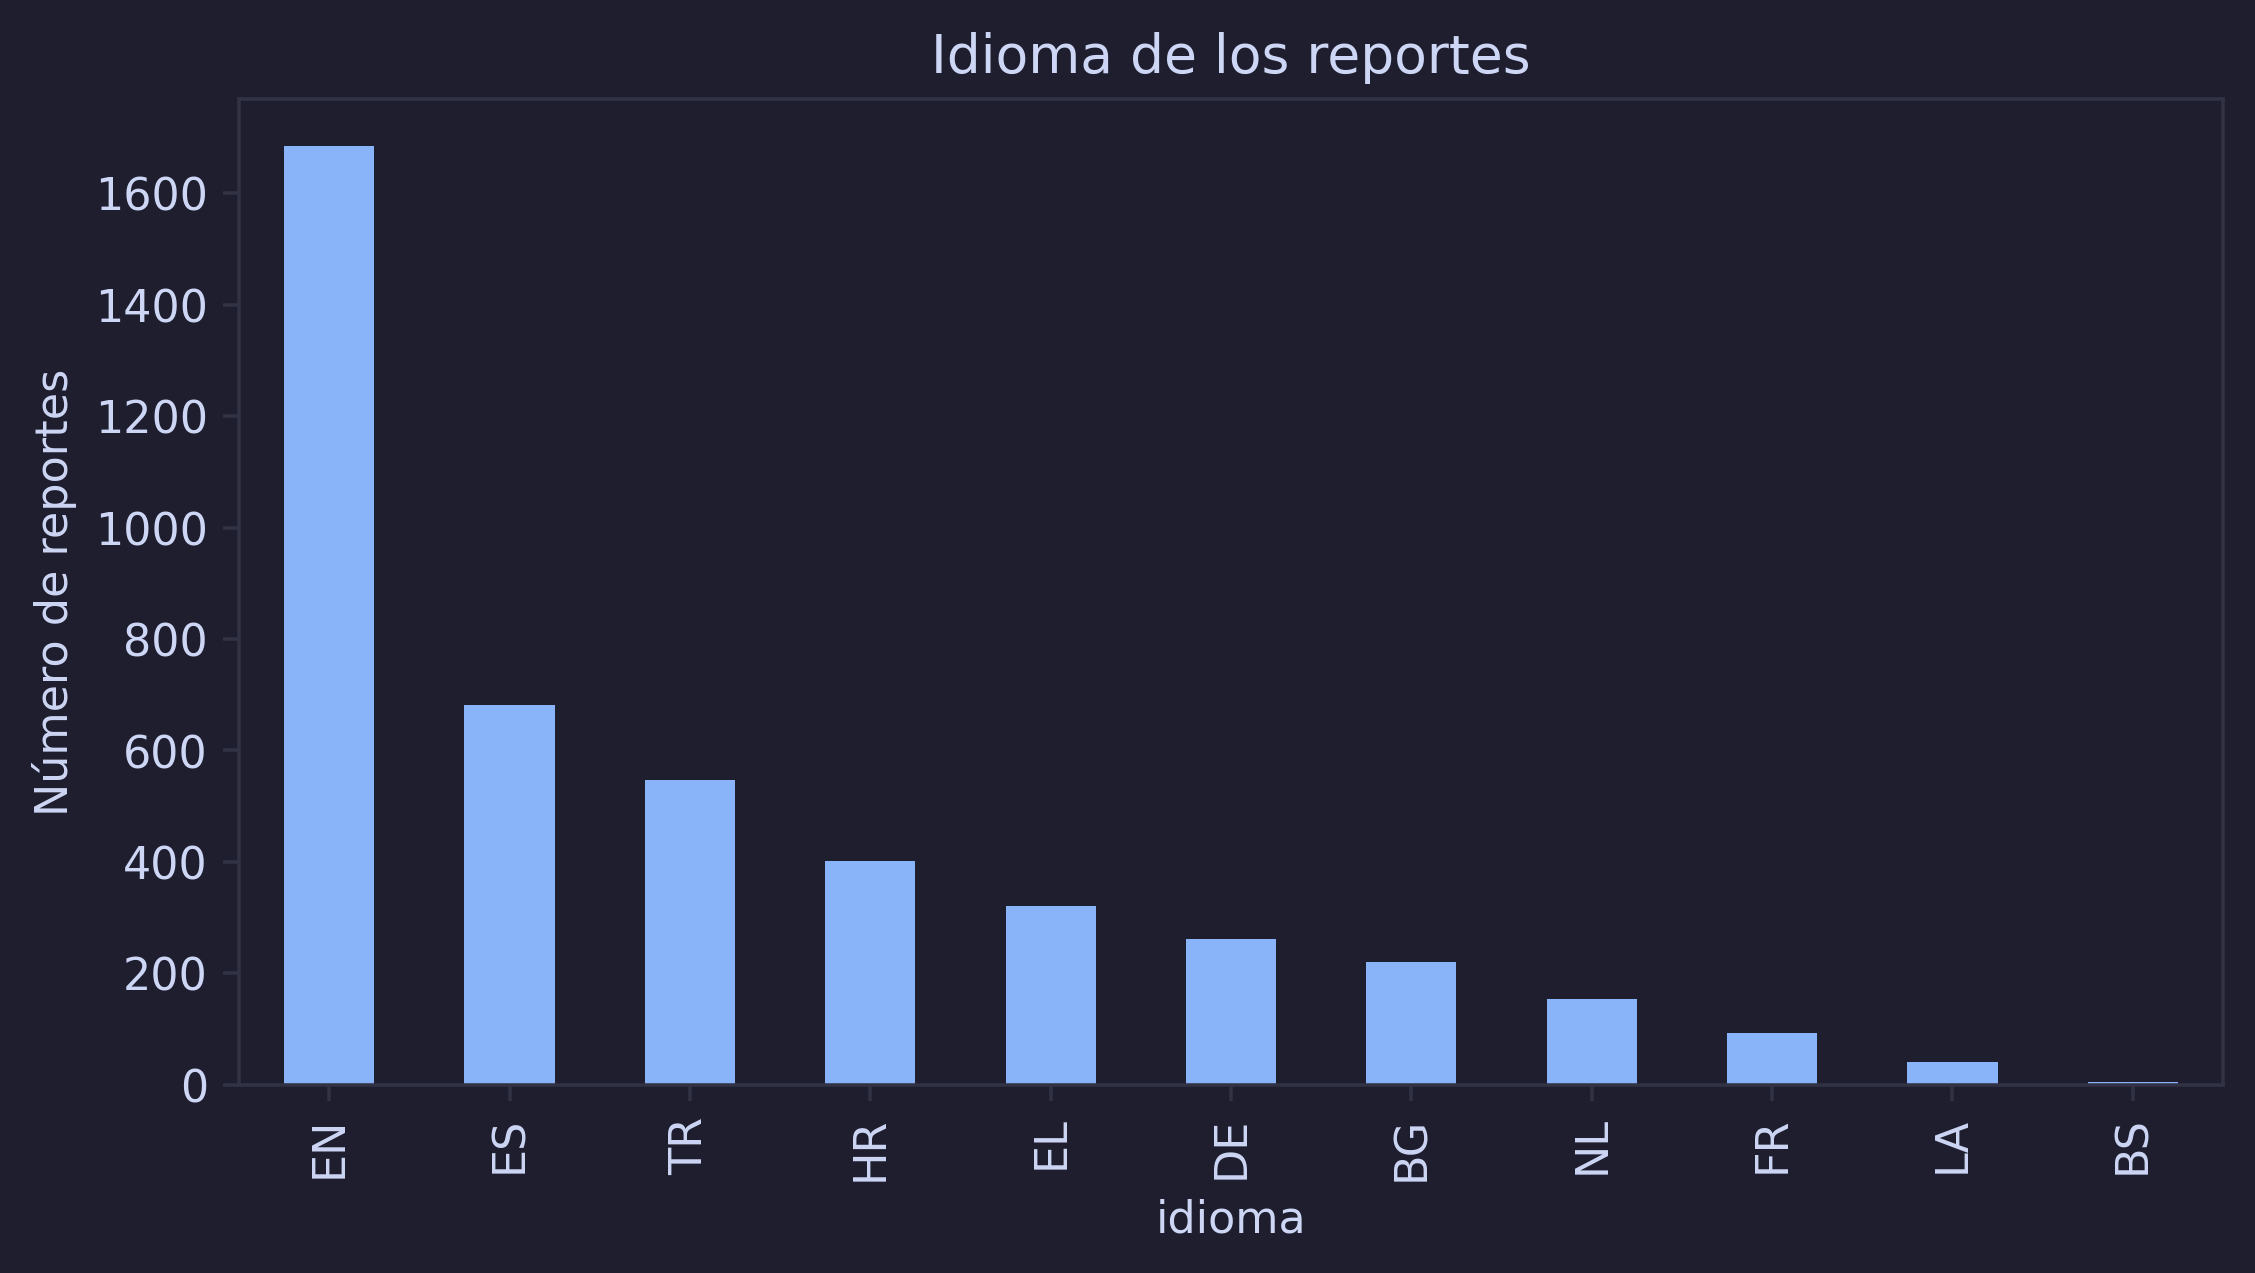

In [26]:
from lingua import LanguageDetectorBuilder

detector = LanguageDetectorBuilder.from_all_languages().with_preloaded_language_models().build()

def idioma(texto):
    lang = detector.detect_language_of(texto)
    return lang.iso_code_639_1.name if lang else None

train["idioma"] = train["Report"].apply(idioma)

plt.figure(figsize=(8, 4), dpi=320)
train["idioma"].value_counts().plot.bar()
plt.ylabel("Número de reportes")
plt.title("Idioma de los reportes")
plt.show()

Son inglés, español, turco, croata, griego, alemán, búlgaro, holandés y francés.

Utilizando la ayuda de Claude, se dio cuenta de que realmente los 40 reportes en Latín eran en inglés, los cuales el modelo marco erroneamente de esta forma.
Igual pasó con los 5 reportes en bosnio que realmente eran croata

In [27]:
train["idioma"] = train["idioma"].replace({"LA": "EN", "BS": "HR"})

### 2.2. Estudios etiquetados (los únicos 58 que están etiquetados)

Estudios etiquetados: 58
idioma
EN    28
ES    10
TR     6
HR     4
EL     3
BG     3
NL     2
DE     2
Name: count, dtype: int64


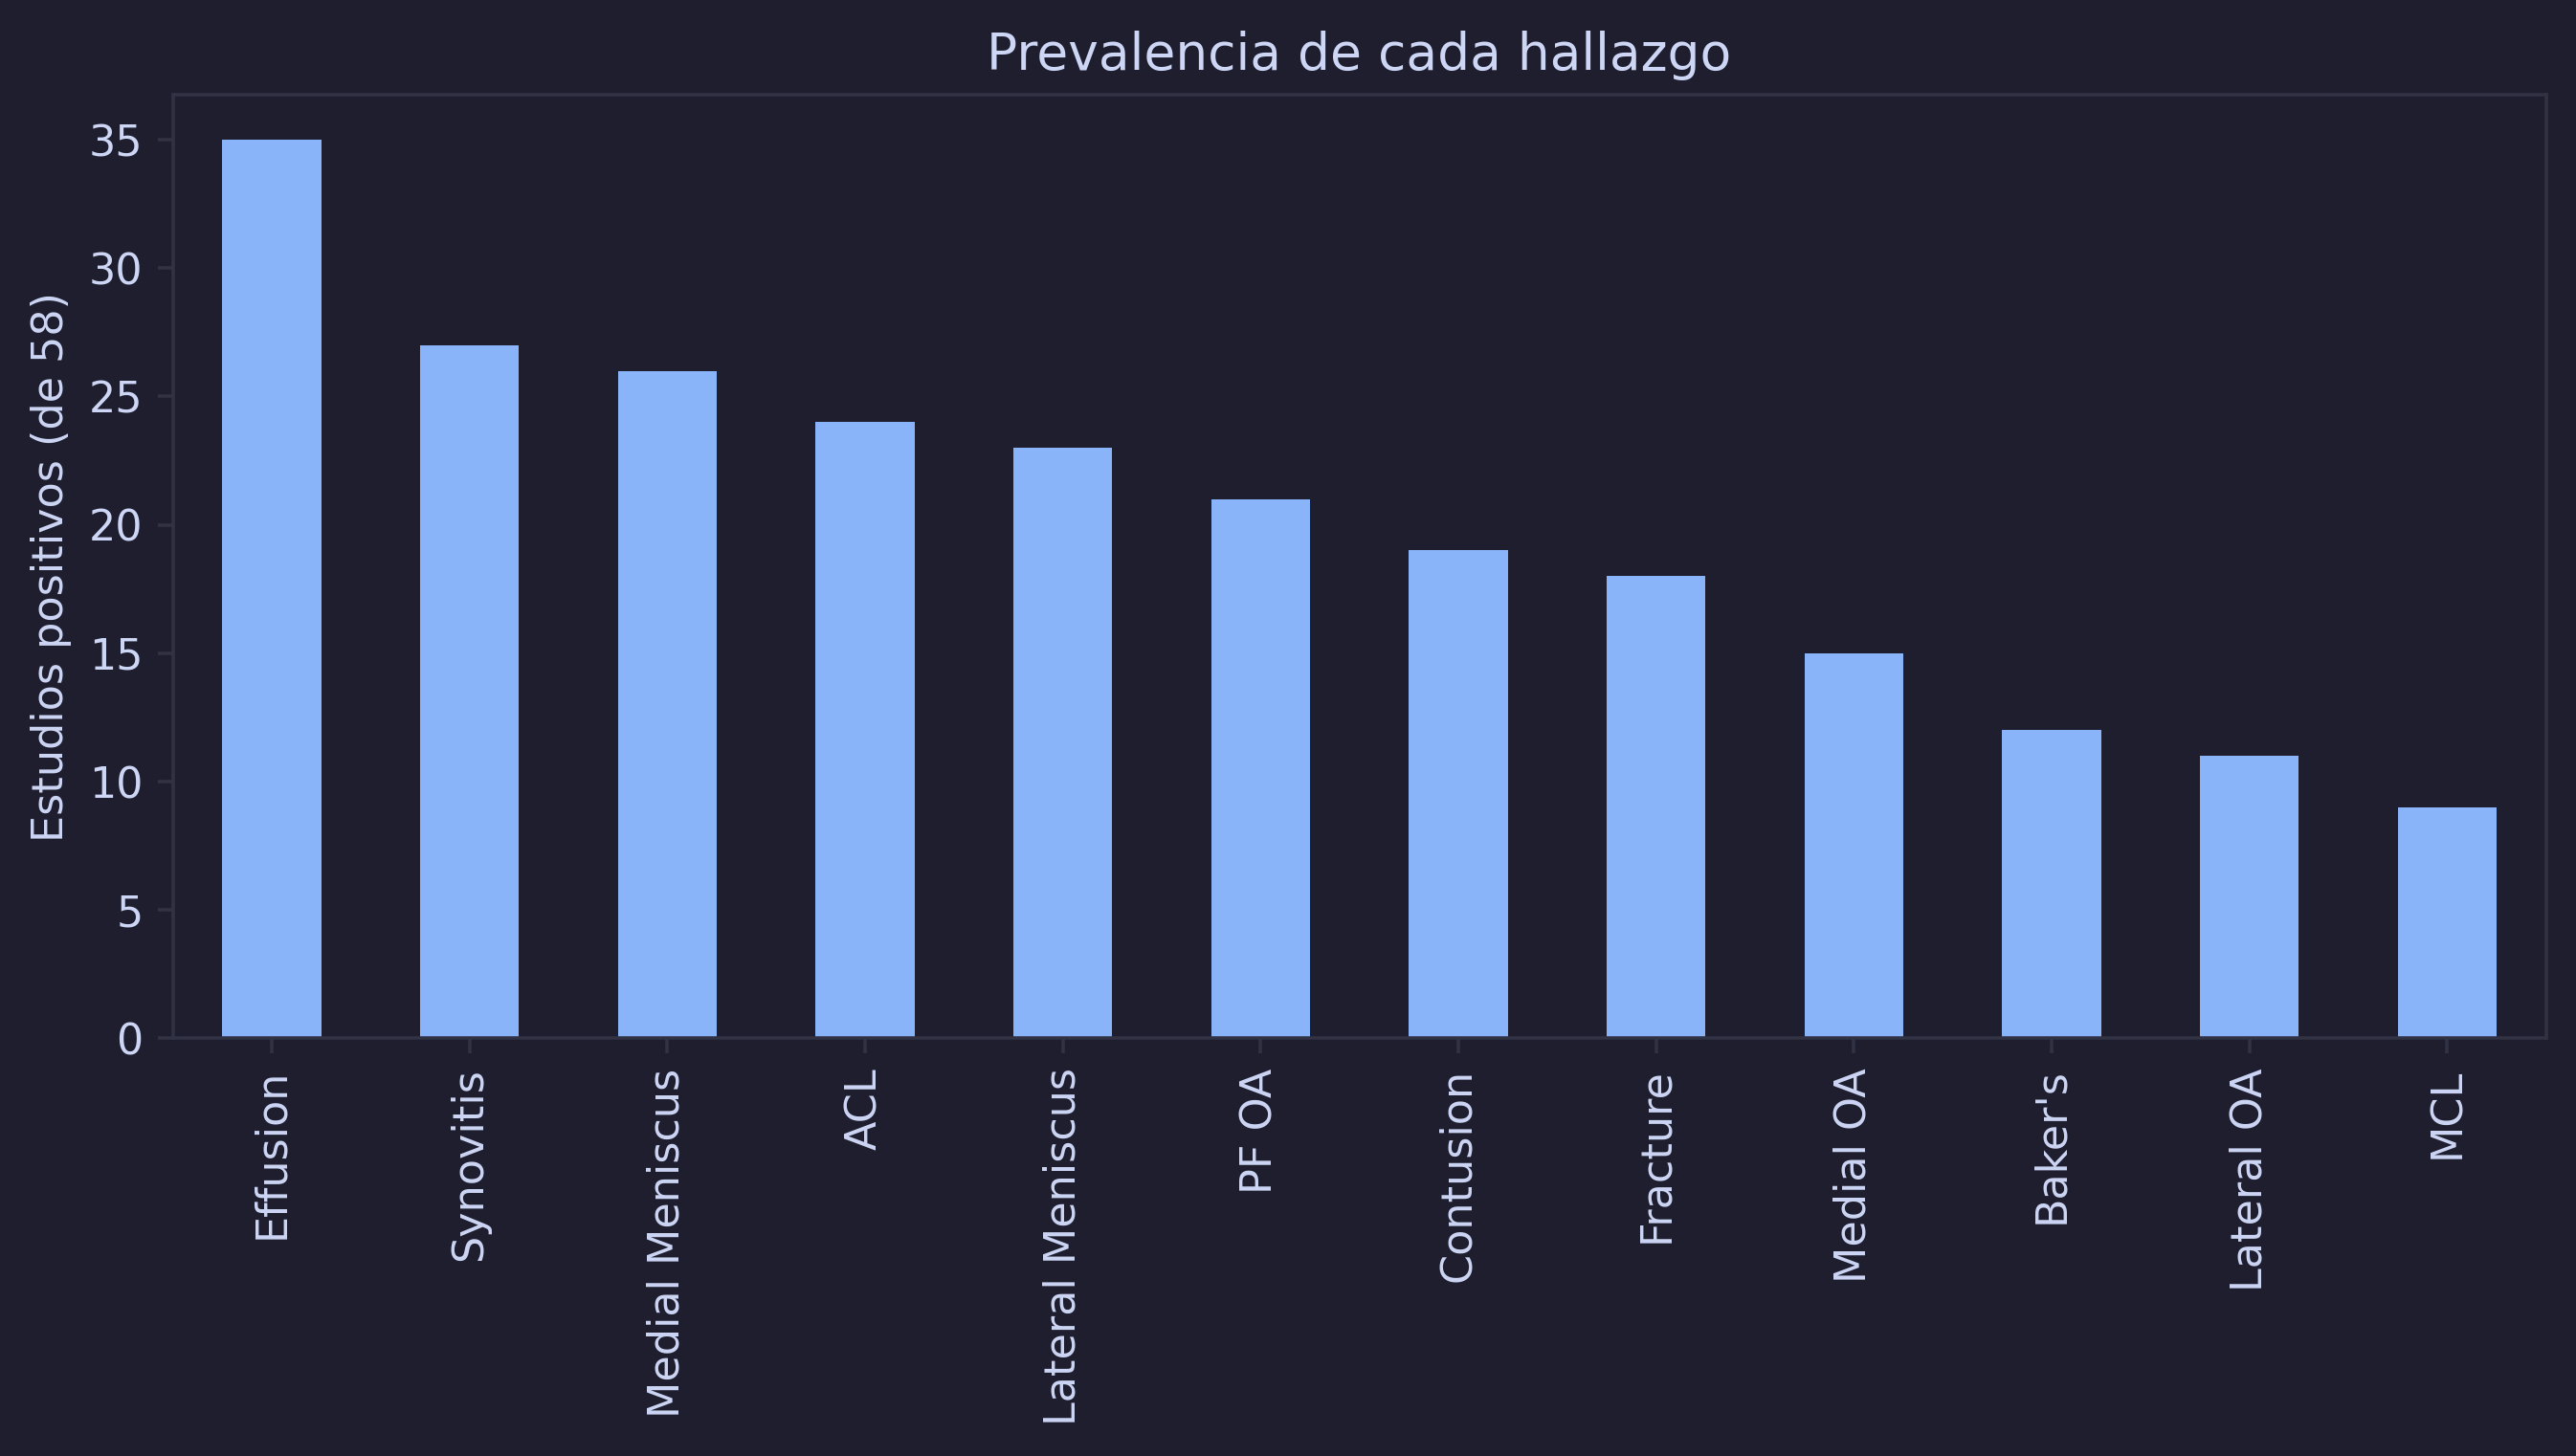

In [30]:
hallazgos = train.columns[2:14]
etiquetados = train.dropna(subset=hallazgos)
y = etiquetados[hallazgos].astype(int)

print("Estudios etiquetados:", len(etiquetados))
print(etiquetados["idioma"].value_counts())

# Prevalencia de cada hallazgo
plt.figure(figsize=(10, 4), dpi=320)
y.sum().sort_values(ascending=False).plot.bar()
plt.ylabel("Estudios positivos (de 58)")
plt.title("Prevalencia de cada hallazgo")
plt.show()

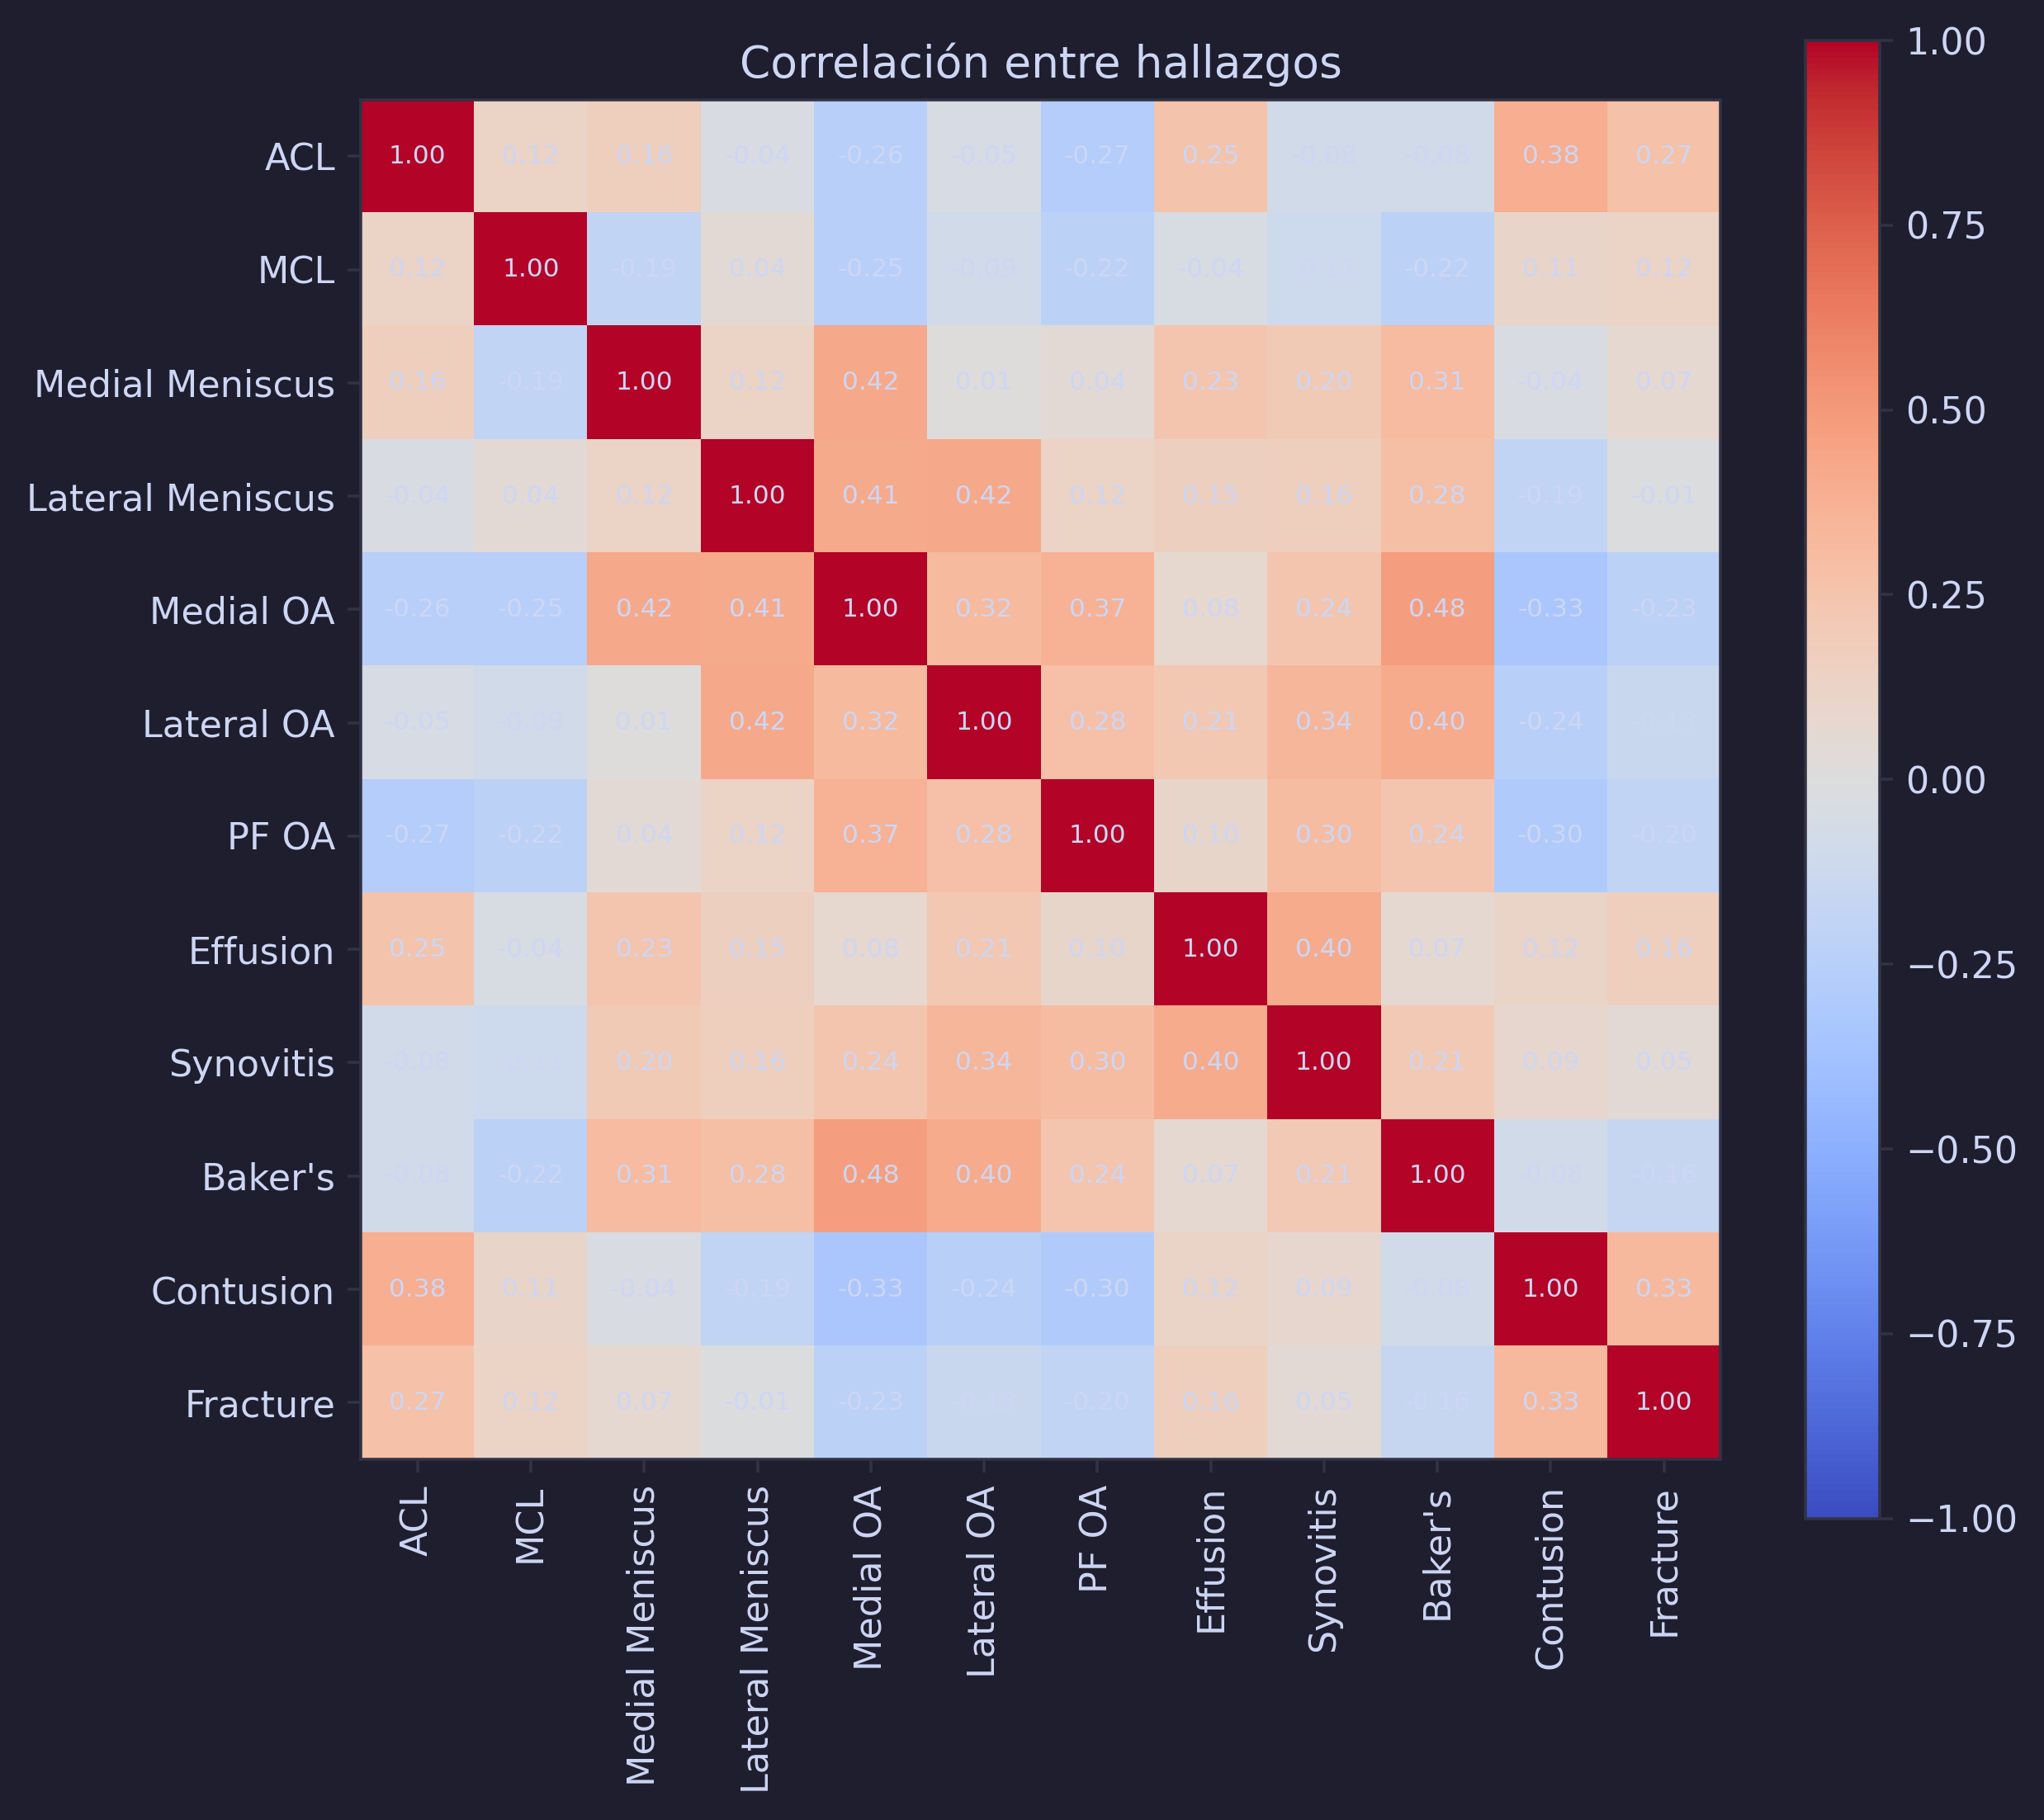

In [31]:
import numpy as np

corr = y.corr()
fig, ax = plt.subplots(figsize=(8, 7), dpi=320)
im = ax.imshow(corr, cmap="coolwarm", vmin=-1, vmax=1)
ax.set_xticks(range(12), hallazgos, rotation=90)
ax.set_yticks(range(12), hallazgos)
for i in range(12):
    for j in range(12):
        ax.text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center", fontsize=7)
fig.colorbar(im)
plt.title("Correlación entre hallazgos")
plt.tight_layout()
plt.show()

#### Hallazgos

1. Las 58 etiquetas están completas (ningún valor faltante) y los 58 estudios tienen reporte, en 9 idiomas y con un 45 % en inglés. Sirven tanto para validar el modelo de imágenes como para medir qué tan bien un LLM extrae etiquetas de los reportes.

2. No están desbalanceadas como cabría esperar. En datos clínicos reales, una fractura es rara, pero aquí entre el 16 % y el 60 % de los estudios son positivos para cada hallazgo. Esto sugiere que Kaggle eligió estos 58 a propósito para tener casos de todo, así que probablemente la prevalencia en test (y en los 4349 sin etiqueta) sea distinta. Es un buen punto para discutir en la sección de validación.

3. Casi todos los estudios tienen varios hallazgos: la mayoría tiene de 3 a 5, y algunos hasta 9. Es un problema multietiqueta, no de clase única. El modelo necesita 12 salidas sigmoides independientes, no un softmax.
4. Las etiquetas forman dos grupos con sentido clínico:
- **Degenerativo**: artrosis, meniscos y quiste de Baker van juntos (Medial OA–Baker's 0.48, Medial Meniscus–Medial OA 0.42, Lateral Meniscus–Lateral OA 0.42).
- **Traumático**: ACL, contusión y fractura van juntos, y son contrarios a la artrosis (Medial OA–Contusion −0.33, ACL–Medial OA −0.26). Tiene sentido: las lesiones traumáticas son de pacientes jóvenes o deportistas, y la artrosis de pacientes mayores.
- El derrame (Effusion) acompaña a casi todo, y sobre todo a la sinovitis (0.40).

Esto es bueno para el modelo: aprender a reconocer un "patrón degenerativo" o un "patrón traumático" ayuda a predecir varias etiquetas a la vez, y una red con salidas compartidas lo aprovecha.

___

___

___

# Conclusiones del EDA

La exploración no fue solo descriptiva: cada hallazgo se traduce en una decisión concreta para el preprocesamiento, la validación o el modelo. La siguiente tabla resume esa relación.

| Hallazgo | Sección | Decisión que implica |
|---|---|---|
| Solo 58 de 4407 estudios tienen etiquetas; los 4349 restantes solo tienen el reporte radiológico | 2.2 | Extraer pseudo-etiquetas de los reportes para entrenar y usar los 58 etiquetados como validación |
| Los reportes están en 9 idiomas; solo el 38 % está en inglés | 2.1 | Traducir los reportes o usar un LLM multilingüe para extraer la información |
| El problema es multietiqueta: la mayoría de los estudios tiene entre 3 y 5 hallazgos | 2.2 | El modelo debe tener 12 salidas sigmoides independientes, no un softmax |
| Los hallazgos forman dos grupos: traumático (ACL, contusión, fractura) y degenerativo (artrosis, meniscos, Baker's) | 2.2 | Una red con salidas compartidas puede aprovechar estas correlaciones |
| Las etiquetas de los 58 están poco desbalanceadas (16 % a 60 % de positivos), lo que sugiere una selección intencional | 2.2 | La prevalencia en test puede ser distinta; tenerlo en cuenta al comparar validación y leaderboard |
| Todos los estudios tienen los 3 planos (sagital, coronal, axial), pero el número de series varía de 3 a 14 | 1.1.2, 1.2.3 | Entrada fija para el modelo: una serie por plano, eligiendo cuál cuando haya varias |
| `Fluid_Sensitive` y `Fat_Suppression` son idénticas en las 24 371 series | 1.2.3 | Usarlas como una sola variable para escoger series |
| Las series 3D tienen de 120 a 320 cortes, contra unos 30 de las 2D | 1.2.2 | Remuestrear a un número fijo de cortes o preferir las series 2D |
| Hay 221 resoluciones distintas, pero el campo de visión es casi siempre de unos 160 mm | 1.3.3.1, 1.3.3.2 | Redimensionar todas las imágenes a un tamaño fijo sin distorsionar la escala física |
| Los cortes miden unos 3 mm con huecos de unos 0.5 mm, contra 0.3 mm por píxel dentro del corte | 1.3.3.3 | Tratar los cortes como imágenes 2D (o 2.5D) en lugar de un volumen 3D |
| Cada fabricante guarda las intensidades en un rango distinto (12 o 16 bits, con o sin signo, Philips escalado) | 1.3.4 | Normalizar las intensidades por serie usando percentiles, no un valor fijo global |
| Todas las series son `MONOCHROME2` | 1.3.4.4 | No hay que invertir ninguna imagen |
| Los nombres de los archivos `.dcm` son UIDs aleatorios | 1.3.1.1 | Ordenar los cortes por `InstanceNumber` al leer una serie |
| Cada estudio tiene un `PatientID` distinto, así que no se pueden detectar pacientes repetidos | 1.3.2.1 | Validar asumiendo que los estudios son independientes y declararlo como limitación |
| La lateralidad falta en la mitad de los estudios y es inconsistente; 1206 series (Toshiba y GE) perdieron casi todos sus parámetros en la anonimización | 1.3.2.3, 1.3 | No usar la metadata clínica como variable del modelo; el modelo se basará solo en las imágenes |

En resumen, los datos tienen dos retos principales. El primero es la **heterogeneidad**: muchas instituciones, fabricantes, idiomas, resoluciones y rangos de intensidad, lo que obliga a estandarizar las imágenes antes de entrenar. El segundo es la **escasez de etiquetas**: con solo 58 estudios etiquetados, la clave del proyecto es aprovechar la información de los reportes radiológicos para etiquetar el resto del conjunto de entrenamiento.